In [1]:
import sys, json, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

try:
    from IPython.display import display
except ImportError:          # plain-python fallback
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# ---- Project root: Google Colab (Drive is mounted here) or local VS Code / Jupyter ----
IN_COLAB = False
try:
    from google.colab import drive          # only exists inside Google Colab
    IN_COLAB = True
except ImportError:
    pass

if IN_COLAB:
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/heatwave-delhi")      # folder must sit directly in My Drive
    ROOT.mkdir(parents=True, exist_ok=True)
else:
    _cwd = Path.cwd().resolve()
    if _cwd.name == "heatwave-delhi":
        ROOT = _cwd
    elif (_cwd / "heatwave-delhi").is_dir():
        ROOT = _cwd / "heatwave-delhi"
    elif _cwd.name == "notebooks":
        ROOT = _cwd.parent
    else:
        ROOT = _cwd
print("Project root:", ROOT)

DIRS = {
    "raw":       ROOT / "data" / "raw",
    "processed": ROOT / "data" / "processed",
    "config":    ROOT / "config",
    "eda":       ROOT / "reports" / "eda",
    "quality":   ROOT / "reports" / "quality",
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: C:\Users\Shreya Mehrotra\Desktop\heatwave-delhi
Project root: C:\Users\Shreya Mehrotra\Desktop\heatwave-delhi


In [2]:
# ----------------------- ALL project settings live here -----------------------
CONFIG = {
    "api_url": "https://archive-api.open-meteo.com/v1/archive",
    "latitude": 28.61,
    "longitude": 77.21,
    "start_date": "2015-01-01",
    "end_date": "2025-12-31",
    "timezone": "Asia/Kolkata",
    "temperature_unit": "celsius",
    "wind_speed_unit": "kmh",
    "models": "era5",
    # Open-Meteo variable -> internal name
    "daily_vars": {
        "temperature_2m_max": "tmax",
        "relative_humidity_2m_mean": "humidity",
        "wind_speed_10m_max": "wind",
        "shortwave_radiation_sum": "solar",
    },
}
VARS = list(CONFIG["daily_vars"].values())            # ['tmax','humidity','wind','solar']
UNITS = {"tmax": "°C", "humidity": "%", "wind": "km/h", "solar": "MJ/m²"}
LABELS = {
    "tmax": "Daily max temperature (°C)",
    "humidity": "Daily mean relative humidity (%)",
    "wind": "Daily max wind speed (km/h)",
    "solar": "Daily shortwave radiation (MJ/m²)",
}
# Units the API should report back (used to validate the response)
EXPECTED_API_UNITS = {"temperature_2m_max": "°C", "relative_humidity_2m_mean": "%",
                      "wind_speed_10m_max": "km/h", "shortwave_radiation_sum": "MJ/m²"}

START, END = pd.Timestamp(CONFIG["start_date"]), pd.Timestamp(CONFIG["end_date"])
FULL_INDEX = pd.date_range(START, END, freq="D", name="date")
EXPECTED_DAYS = len(FULL_INDEX)
assert EXPECTED_DAYS == 4018, EXPECTED_DAYS

# Chronological periods (by TARGET date, used later in notebook 02)
TRAIN_END = pd.Timestamp("2022-12-31")      # lag / ACF analysis is limited to <= this date

# Validity rules. HARD = physically impossible -> converted to NaN in Phase D.
HARD_RULES = {"tmax": (-20, 60), "humidity": (0, 100), "wind": (0, None), "solar": (0, None)}
# WARN = unusual for Delhi -> only flagged for investigation, never auto-deleted.
WARN_RANGES = {"tmax": (0, 50), "humidity": (3, 100), "wind": (0, 80), "solar": (0, 35)}

# Exploratory thresholds (NOT an official heatwave definition)
HOT_THRESHOLDS = [35, 40, 42, 45, 47]

FORCE_DOWNLOAD = False      # True = re-download and overwrite the raw file
print("Expected days:", EXPECTED_DAYS, "| variables:", VARS)

Expected days: 4018 | variables: ['tmax', 'humidity', 'wind', 'solar']


In [3]:
RAW_CSV = DIRS["raw"] / "delhi_daily_raw.csv"
META_JSON = DIRS["config"] / "dataset_metadata.json"


def fetch_archive(cfg):
    # Call the Open-Meteo archive API. Fails loudly - never silently switches model/source.
    params = {
        "latitude": cfg["latitude"], "longitude": cfg["longitude"],
        "start_date": cfg["start_date"], "end_date": cfg["end_date"],
        "daily": ",".join(cfg["daily_vars"].keys()),
        "timezone": cfg["timezone"],
        "temperature_unit": cfg["temperature_unit"],
        "wind_speed_unit": cfg["wind_speed_unit"],
        "models": cfg["models"],
    }
    try:
        resp = requests.get(cfg["api_url"], params=params, timeout=120)
    except requests.RequestException as err:
        raise RuntimeError(f"Network/API request failed: {err}") from err
    if resp.status_code != 200:
        raise RuntimeError(f"Open-Meteo returned HTTP {resp.status_code}: {resp.text[:400]}")
    return resp.json(), params


def find_key(block, var, model):
    # With one model the key is the plain name; some responses suffix it with the model.
    for key in (var, f"{var}_{model}"):
        if key in block:
            return key
    return None


def validate_response(payload, cfg):
    # Returns a list of (check, passed, detail). Covers checks 1-8 of Step A3.
    out = []
    daily = payload.get("daily")
    units = payload.get("daily_units", {})
    out.append(("'daily' object exists", isinstance(daily, dict), ""))
    if not isinstance(daily, dict):
        return out
    out.append(("'time' array exists", "time" in daily, ""))
    keys = {v: find_key(daily, v, cfg["models"]) for v in cfg["daily_vars"]}
    missing = [v for v, k in keys.items() if k is None]
    out.append(("all 4 variable arrays present", not missing, f"missing: {missing}" if missing else ""))
    if "time" not in daily or missing:
        return out
    lengths = {"time": len(daily["time"]), **{v: len(daily[k]) for v, k in keys.items()}}
    out.append(("all arrays equal length", len(set(lengths.values())) == 1, str(lengths)))
    try:
        dates = pd.to_datetime(daily["time"], format="%Y-%m-%d")
        out.append(("dates parse as YYYY-MM-DD", True, ""))
        out.append(("range covers requested period",
                    dates.min() == pd.Timestamp(cfg["start_date"]) and dates.max() == pd.Timestamp(cfg["end_date"]),
                    f"{dates.min().date()} -> {dates.max().date()}"))
    except Exception as err:
        out.append(("dates parse as YYYY-MM-DD", False, str(err)))
    for v, expected in EXPECTED_API_UNITS.items():
        reported = units.get(keys[v], units.get(v))
        out.append((f"unit of {v}", reported == expected, f"API says {reported!r}, expected {expected!r}"))
    return out


def build_dataframe(payload, cfg):
    daily = payload["daily"]
    data = {"date": pd.to_datetime(daily["time"])}
    for var, name in cfg["daily_vars"].items():
        data[name] = pd.to_numeric(pd.Series(daily[find_key(daily, var, cfg["models"])]), errors="coerce")
    return pd.DataFrame(data)

In [4]:
if RAW_CSV.exists() and not FORCE_DOWNLOAD:
    print(f"Raw file already exists -> loading (immutable): {RAW_CSV.name}")
    raw = pd.read_csv(RAW_CSV, parse_dates=["date"])
    api_checks = None
else:
    payload, params = fetch_archive(CONFIG)
    api_checks = validate_response(payload, CONFIG)
    check_table = pd.DataFrame(api_checks, columns=["check", "passed", "detail"])
    display(check_table)
    if not check_table["passed"].all():
        raise RuntimeError("API response validation failed - fix the request instead of changing source silently.")

    raw = build_dataframe(payload, CONFIG)
    raw.to_csv(RAW_CSV, index=False)                        # saved BEFORE any cleaning

    metadata = {
        "source": "Open-Meteo Historical Weather Archive API",
        "source_model": CONFIG["models"],
        "api_url": CONFIG["api_url"],
        "request_params": params,
        "variables": {v: {"internal_name": n, "unit": UNITS[n]} for v, n in CONFIG["daily_vars"].items()},
        "api_reported_units": payload.get("daily_units"),
        "location": {"name": "Central Delhi, India", "latitude": CONFIG["latitude"], "longitude": CONFIG["longitude"],
                     "grid_cell_returned": {"latitude": payload.get("latitude"), "longitude": payload.get("longitude"),
                                            "elevation": payload.get("elevation")}},
        "timezone": CONFIG["timezone"],
        "frequency": "daily", "expected_rows": EXPECTED_DAYS,
        "retrieval_date_utc": datetime.utcnow().strftime("%Y-%m-%d %H:%M:%S"),
        "api_response_validation": [{"check": c, "passed": bool(p), "detail": d} for c, p, d in api_checks],
        "disclaimer": "Values are model-derived (ERA5 reanalysis) estimates for the nearest grid cell, "
                      "not physical weather-station observations. Historical Archive data and operational "
                      "Forecast API data may come from different model products - validate before live use.",
    }
    META_JSON.write_text(json.dumps(metadata, indent=2, ensure_ascii=False))
    print("Saved:", RAW_CSV, "and", META_JSON)

print(raw.shape)
raw.head()

Raw file already exists -> loading (immutable): delhi_daily_raw.csv
(4018, 5)


,date,tmax,humidity,wind,solar
0,2015-01-01,21.0,73,8.9,10.17
1,2015-01-02,15.9,88,11.2,4.91
2,2015-01-03,16.6,91,9.0,4.59
3,2015-01-04,18.1,85,13.5,12.68
4,2015-01-05,20.4,78,27.0,14.72


In [5]:
df_raw = pd.read_csv(RAW_CSV, parse_dates=["date"])      # always inspect the file on disk

print("First 10 rows"); display(df_raw.head(10))
print("Last 10 rows");  display(df_raw.tail(10))
print(f"Rows: {df_raw.shape[0]} | Columns: {df_raw.shape[1]}")
print("Columns:", list(df_raw.columns))
print("Memory usage: %.1f KB" % (df_raw.memory_usage(deep=True).sum() / 1024))
print("First date:", df_raw["date"].min().date(), "| Last date:", df_raw["date"].max().date())
print()
df_raw.info()

First 10 rows


,date,tmax,humidity,wind,solar
0,2015-01-01,21.0,73,8.9,10.17
1,2015-01-02,15.9,88,11.2,4.91
2,2015-01-03,16.6,91,9.0,4.59
3,2015-01-04,18.1,85,13.5,12.68
4,2015-01-05,20.4,78,27.0,14.72
5,2015-01-06,18.1,80,21.7,12.46
6,2015-01-07,16.7,83,11.3,8.16
7,2015-01-08,17.5,87,9.4,14.20
8,2015-01-09,17.1,88,9.4,14.30
9,2015-01-10,17.0,83,13.8,14.77


Last 10 rows


,date,tmax,humidity,wind,solar
4008,2025-12-22,19.3,91,8.8,10.16
4009,2025-12-23,22.7,84,15.9,14.00
4010,2025-12-24,21.4,75,15.0,14.34
4011,2025-12-25,20.3,73,8.8,14.37
4012,2025-12-26,21.4,76,9.2,12.82
4013,2025-12-27,20.0,83,11.2,13.05
4014,2025-12-28,19.4,86,9.4,14.16
4015,2025-12-29,18.2,90,8.2,12.71
4016,2025-12-30,18.5,87,9.2,12.99
4017,2025-12-31,17.8,93,13.5,12.51


Rows: 4018 | Columns: 5
Columns: ['date', 'tmax', 'humidity', 'wind', 'solar']
Memory usage: 157.1 KB
First date: 2015-01-01 | Last date: 2025-12-31

<class 'pandas.DataFrame'>
RangeIndex: 4018 entries, 0 to 4017
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      4018 non-null   datetime64[us]
 1   tmax      4018 non-null   float64       
 2   humidity  4018 non-null   int64         
 3   wind      4018 non-null   float64       
 4   solar     4018 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(1)
memory usage: 157.1 KB


DESCRIPTIVE STATISTICS


In [6]:
def full_describe(frame, cols):
    rows = {}
    for c in cols:
        s = frame[c].dropna()
        mode = s.round(1).mode()
        rows[c] = {
            "count": s.count(), "mean": s.mean(), "median": s.median(),
            "mode (0.1 rounded)": mode.iloc[0] if len(mode) else np.nan,
            "min": s.min(), "max": s.max(), "range": s.max() - s.min(),
            "variance": s.var(), "std": s.std(),
            "25%": s.quantile(.25), "50%": s.quantile(.50), "75%": s.quantile(.75),
            "IQR": s.quantile(.75) - s.quantile(.25),
            "skewness": s.skew(), "kurtosis (excess)": s.kurt(),
        }
    return pd.DataFrame(rows).T.round(3)

stats_raw = full_describe(df_raw, VARS)
stats_raw

,count,mean,median,mode (0.1 rounded),min,max,range,variance,std,25%,50%,75%,IQR,skewness,kurtosis (excess)
tmax,4018.0,31.100,32.40,34.3,10.3,46.50,36.20,46.360,6.809,26.20,32.40,35.600,9.400,-0.381,-0.459
humidity,4018.0,66.961,70.00,74.0,21.0,99.00,78.00,256.879,16.027,58.00,70.00,79.000,21.000,-0.674,-0.217
wind,4018.0,13.767,13.00,9.4,5.5,32.30,26.80,20.686,4.548,10.20,13.00,16.400,6.200,0.899,0.753
solar,4018.0,18.599,18.37,14.5,1.2,29.21,28.01,26.474,5.145,14.84,18.37,22.625,7.785,-0.171,-0.279


CHECKING


In [7]:
dates = df_raw["date"]
missing_dates = FULL_INDEX.difference(pd.DatetimeIndex(dates))
extra_dates = pd.DatetimeIndex(dates).difference(FULL_INDEX)
leap_days = sorted(d.date() for d in FULL_INDEX if d.month == 2 and d.day == 29)
leap_present = sorted(d.date() for d in dates if d.month == 2 and d.day == 29)
gaps = dates.sort_values().diff().dropna()

date_report = {
    "expected dates": EXPECTED_DAYS,
    "rows in file": len(df_raw),
    "missing dates": len(missing_dates),
    "duplicate dates": int(dates.duplicated().sum()),
    "dates outside requested period": len(extra_dates),
    "in chronological order": bool(dates.is_monotonic_increasing),
    "unexpected gaps (diff != 1 day)": int((gaps != pd.Timedelta(days=1)).sum()),
    "leap days expected / present": f"{len(leap_days)} / {len(leap_present)}  ({leap_days == leap_present})",
}
pd.Series(date_report, name="value").to_frame()

,value
expected dates,4018
rows in file,4018
missing dates,0
duplicate dates,0
dates outside requested period,0
in chronological order,True
unexpected gaps (diff != 1 day),0
leap days expected / present,3 / 3 (True)


COLUMN ANALYSIS

In [8]:
completeness = pd.DataFrame({
    "non_null": df_raw[VARS].notna().sum(),
    "null": df_raw[VARS].isna().sum(),
    "coverage_%": (df_raw[VARS].notna().mean() * 100).round(3),
})
completeness

,non_null,null,coverage_%
tmax,4018,0,100.0
humidity,4018,0,100.0
wind,4018,0,100.0
solar,4018,0,100.0


DATA QUALITY ANALYSIS

In [9]:
cal = (df_raw.drop_duplicates("date").set_index("date").reindex(FULL_INDEX))[VARS]


def run_lengths(mask):
    # Consecutive-True runs in a boolean Series indexed by date -> start, end, length.
    m = pd.Series(np.asarray(mask), index=mask.index)
    grp = (m != m.shift()).cumsum()
    runs = [(g.index[0], g.index[-1], len(g)) for _, g in m.groupby(grp) if g.iloc[0]]
    return pd.DataFrame(runs, columns=["start", "end", "length"])


def save_fig(name, folder="eda"):
    path = DIRS[folder] / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("saved ->", path.relative_to(ROOT))

MISSING VALUES

,missing,missing_%
tmax,0,0.0
humidity,0,0.0
wind,0,0.0
solar,0,0.0


Rows missing >=1 variable : 0
Rows missing ALL variables: 0

Consecutive missing-day runs (any variable):


'none'

Dates with any missing value: [] ...
saved -> reports\quality\c1_missing_values.png


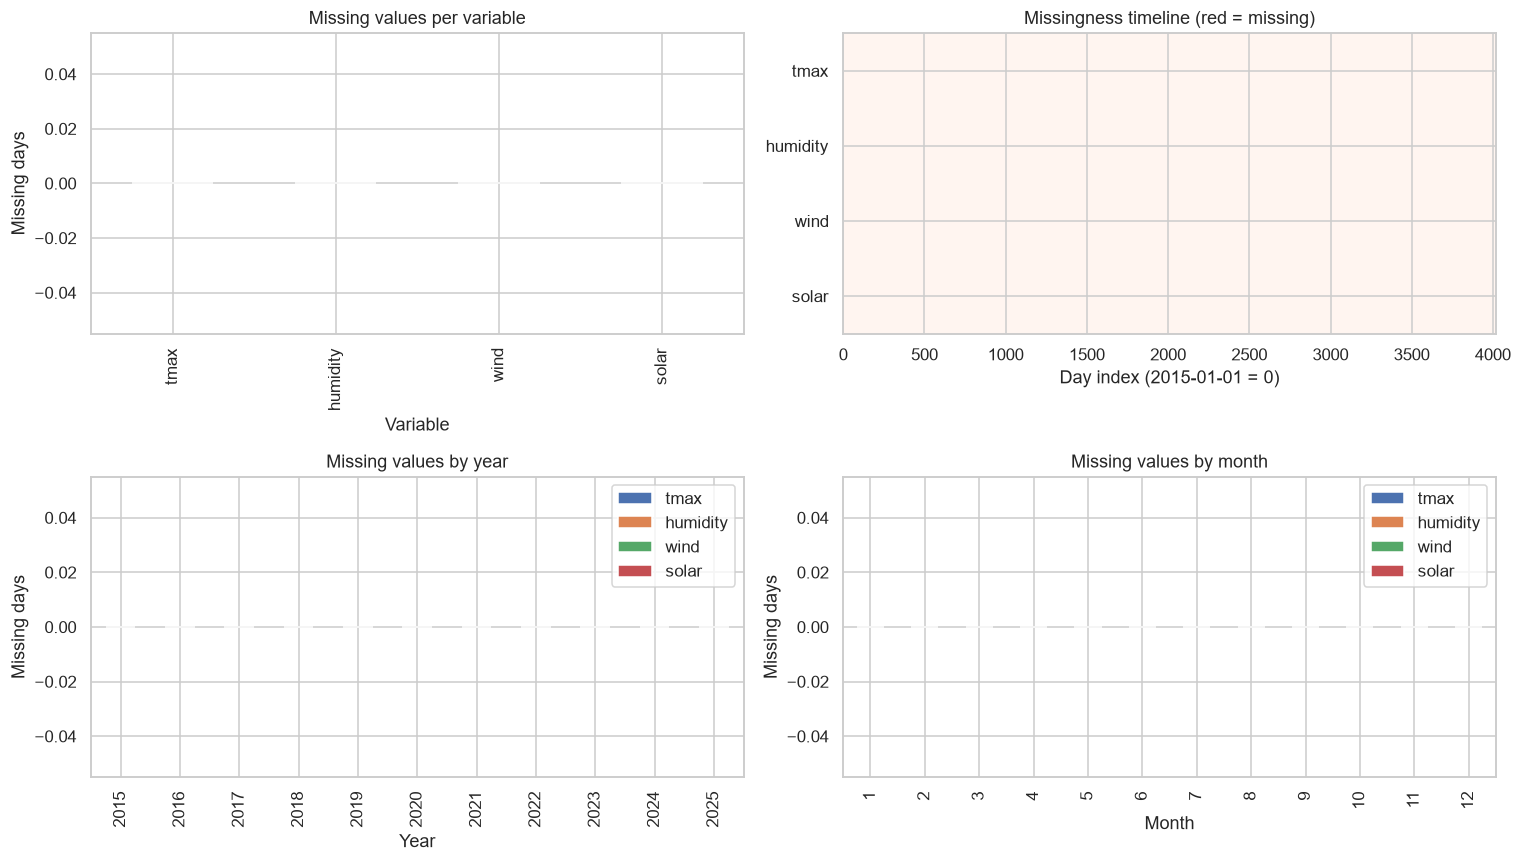

In [10]:
na = cal.isna()
missing_summary = pd.DataFrame({"missing": na.sum(), "missing_%": (na.mean() * 100).round(3)})
display(missing_summary)
print("Rows missing >=1 variable :", int(na.any(axis=1).sum()))
print("Rows missing ALL variables:", int(na.all(axis=1).sum()))

by_year = na.groupby(na.index.year).sum()
by_month = na.groupby(na.index.month).sum()

print("\nConsecutive missing-day runs (any variable):")
runs_any = run_lengths(na.any(axis=1))
display(runs_any.sort_values("length", ascending=False).head(10) if len(runs_any) else "none")
print("Dates with any missing value:", [d.date() for d in na.index[na.any(axis=1)][:20]], "...")

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
na.sum().plot.bar(ax=ax[0, 0], color="tab:red"); ax[0, 0].set_title("Missing values per variable")
ax[0, 0].set_xlabel("Variable"); ax[0, 0].set_ylabel("Missing days")
ax[0, 1].imshow(na.T.values, aspect="auto", cmap="Reds", interpolation="nearest",
                extent=[0, len(na), 0, len(VARS)])
ax[0, 1].set_yticks(np.arange(len(VARS)) + .5); ax[0, 1].set_yticklabels(VARS[::-1])
ax[0, 1].set_title("Missingness timeline (red = missing)"); ax[0, 1].set_xlabel("Day index (2015-01-01 = 0)")
by_year.plot.bar(ax=ax[1, 0]); ax[1, 0].set_title("Missing values by year")
ax[1, 0].set_xlabel("Year"); ax[1, 0].set_ylabel("Missing days")
by_month.plot.bar(ax=ax[1, 1]); ax[1, 1].set_title("Missing values by month")
ax[1, 1].set_xlabel("Month"); ax[1, 1].set_ylabel("Missing days")
plt.tight_layout(); save_fig("c1_missing_values", "quality"); plt.show()

DUPLICATES AND NUMERICAL VALIDITY

In [11]:
dup_rows = df_raw.duplicated().sum()
dup_dates = df_raw.duplicated("date", keep=False)
conflicting = df_raw[dup_dates & ~df_raw.duplicated(keep=False)]
print(f"Exact duplicate rows: {dup_rows} | rows sharing a date: {int(dup_dates.sum())} | conflicting-value duplicates: {len(conflicting)}")

# C3: re-read as text to catch non-numeric strings that pandas could silently coerce
txt = pd.read_csv(RAW_CSV, dtype=str)
validity = {}
for c in VARS:
    as_num = pd.to_numeric(txt[c], errors="coerce")
    validity[c] = {
        "non-numeric strings": int((as_num.isna() & txt[c].notna()).sum()),
        "infinite values": int(np.isinf(as_num).sum()),
        "null values": int(txt[c].isna().sum()),
        "dtype in parsed file": str(df_raw[c].dtype),
    }
display(pd.DataFrame(validity).T)

if api_checks is None and META_JSON.exists():
    reported = json.loads(META_JSON.read_text()).get("api_reported_units")
    print("Units reported by API at download time:", reported)

Exact duplicate rows: 0 | rows sharing a date: 0 | conflicting-value duplicates: 0


,non-numeric strings,infinite values,null values,dtype in parsed file
tmax,0,0,0,float64
humidity,0,0,0,int64
wind,0,0,0,float64
solar,0,0,0,float64


Units reported by API at download time: {'time': 'iso8601', 'temperature_2m_max': '°C', 'relative_humidity_2m_mean': '%', 'wind_speed_10m_max': 'km/h', 'shortwave_radiation_sum': 'MJ/m²'}


PLAUSIBILITY AND OUTLIER ANALYSIS

In [12]:
# ---- C4: hard rules (impossible) and warning ranges (unusual only) ----
rows = []
for v in VARS:
    s = cal[v]
    hlo, hhi = HARD_RULES[v]
    wlo, whi = WARN_RANGES[v]
    hard = ((s < hlo) if hlo is not None else False) | ((s > hhi) if hhi is not None else False)
    warn = ((s < wlo) | (s > whi)) & ~hard
    rows.append({"variable": v, "hard-rule violations": int(hard.sum()), "warning-range flags": int(warn.sum()),
                 "min": s.min(), "max": s.max()})
plaus = pd.DataFrame(rows).set_index("variable")
display(plaus)

,hard-rule violations,warning-range flags,min,max
variable,,,,
tmax,0,0,10.3,46.50
humidity,0,0,21.0,99.00
wind,0,0,5.5,32.30
solar,0,0,1.2,29.21


,iqr,zscore,seasonal_anomaly,day_jump,vs_neighbours
tmax,3,1,18,8,3
humidity,21,0,21,3,3
wind,75,43,31,0,0
solar,9,9,73,116,68


Tmax days flagged by >=2 methods (review, do NOT auto-delete): 6


,tmax,iqr,zscore,seasonal_anomaly,day_jump,vs_neighbours,n_methods
date,,,,,,,
2019-12-30,10.3,True,True,True,False,False,3
2015-06-25,27.9,False,False,False,True,True,2
2019-12-28,11.8,True,False,True,False,False,2
2019-12-29,11.8,True,False,True,False,False,2
2021-07-19,26.7,False,False,False,True,True,2
2021-10-18,23.7,False,False,True,False,True,2


saved -> reports\quality\c5_boxplots.png


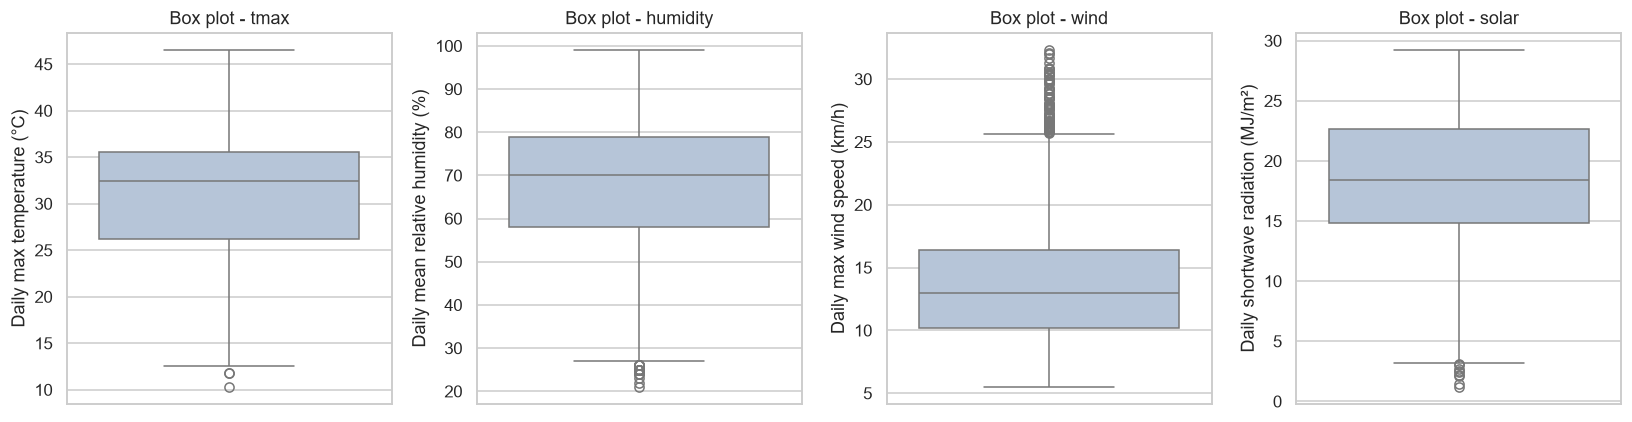

In [13]:
# ---- C5: several independent outlier methods (all are for INVESTIGATION only) ----
def seasonal_anomaly(series, ref=None):
    # Value minus a smoothed day-of-year climatology (31-day circular smoothing).
    # ref = series used to build the climatology (defaults to the series itself).
    ref = series if ref is None else ref
    md_ref = ref.index.strftime("%m-%d")
    clim = ref.groupby(md_ref).mean().sort_index()
    pad = 15
    ext = pd.concat([clim.iloc[-pad:], clim, clim.iloc[:pad]])
    smooth = ext.rolling(31, center=True, min_periods=1).mean().iloc[pad:-pad]
    smooth.index = clim.index
    return series - smooth.reindex(series.index.strftime("%m-%d")).values


def outlier_flags(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    f = pd.DataFrame(index=s.index)
    f["iqr"] = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    f["zscore"] = ((s - s.mean()) / s.std()).abs() > 3
    anom = seasonal_anomaly(s)
    z_by_month = anom / anom.groupby(anom.index.month).transform("std")
    f["seasonal_anomaly"] = z_by_month.abs() > 3
    d = s.diff()
    mad = (d - d.median()).abs().median() * 1.4826
    f["day_jump"] = ((d - d.median()).abs() / mad) > 6
    neighbours = (s.shift(1) + s.shift(-1)) / 2
    nd = (s - neighbours)
    nmad = (nd - nd.median()).abs().median() * 1.4826
    f["vs_neighbours"] = ((nd - nd.median()).abs() / nmad) > 6
    return f.fillna(False)

flags = {v: outlier_flags(cal[v]) for v in VARS}
outlier_summary = pd.DataFrame({v: flags[v].sum() for v in VARS}).T
display(outlier_summary)

# Dates of tmax flagged by >= 2 methods -> manual review list
tf = flags["tmax"]
review = tf[tf.sum(axis=1) >= 2].copy()
review.insert(0, "tmax", cal.loc[review.index, "tmax"])
review["n_methods"] = tf.loc[review.index].sum(axis=1)
print("Tmax days flagged by >=2 methods (review, do NOT auto-delete):", len(review))
display(review.sort_values("n_methods", ascending=False).head(20))

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, v in zip(ax, VARS):
    sns.boxplot(y=cal[v], ax=a, color="lightsteelblue"); a.set_title(f"Box plot - {v}")
    a.set_ylabel(LABELS[v]); a.set_xlabel("")
plt.tight_layout(); save_fig("c5_boxplots", "quality"); plt.show()

DATA QUALITY REPORT

In [14]:
quality_report = f"""# Data Quality Report - Delhi Daily Weather (raw)
Generated: {datetime.now():%Y-%m-%d %H:%M}

## Coverage
- Rows in raw file: {len(df_raw)} (expected {EXPECTED_DAYS})
- Missing dates: {date_report['missing dates']} | duplicate dates: {date_report['duplicate dates']}
- Chronological: {date_report['in chronological order']} | unexpected gaps: {date_report['unexpected gaps (diff != 1 day)']}

## Missing values
{missing_summary.to_string()}

## Duplicates
- Exact duplicate rows: {dup_rows} | conflicting duplicate dates: {len(conflicting)}

## Physical validity
{plaus.to_string()}

## Outlier flags (investigation only)
{outlier_summary.to_string()}
- Tmax days flagged by >=2 methods: {len(review)}

## Recommended cleaning actions
1. Standardise dtypes/order; remove exact duplicates (stop on conflicting duplicates).
2. Reindex to the full 4,018-day calendar so gaps stay explicit.
3. Convert hard-rule violations to NaN (audited). No imputation here.
4. Keep all genuine hot extremes; no smoothing.
"""
(DIRS["quality"] / "data_quality_report.md").write_text(quality_report)
print(quality_report)

# Data Quality Report - Delhi Daily Weather (raw)
Generated: 2026-11-22 19:18

## Coverage
- Rows in raw file: 4018 (expected 4018)
- Missing dates: 0 | duplicate dates: 0
- Chronological: True | unexpected gaps: 0

## Missing values
          missing  missing_%
tmax            0        0.0
humidity        0        0.0
wind            0        0.0
solar           0        0.0

## Duplicates
- Exact duplicate rows: 0 | conflicting duplicate dates: 0

## Physical validity
          hard-rule violations  warning-range flags   min    max
variable                                                        
tmax                         0                    0  10.3  46.50
humidity                     0                    0  21.0  99.00
wind                         0                    0   5.5  32.30
solar                        0                    0   1.2  29.21

## Outlier flags (investigation only)
          iqr  zscore  seasonal_anomaly  day_jump  vs_neighbours
tmax        3       1          

GENERAL DATA CLEANING

In [15]:
audit = []

def log_change(date, var, old, new, reason, method):
    audit.append({"date": date, "variable": var, "original_value": old, "modified_value": new,
                  "reason": reason, "method": method})

clean = df_raw.copy()

# D1: standard formats
clean["date"] = pd.to_datetime(clean["date"])
clean = clean[["date"] + VARS].sort_values("date")
for c in VARS:
    clean[c] = pd.to_numeric(clean[c], errors="coerce")

# D2: duplicates
n_exact = int(clean.duplicated().sum())
clean = clean.drop_duplicates()
conflicts = clean[clean.duplicated("date", keep=False)]
if len(conflicts):
    display(conflicts)
    raise ValueError("Conflicting duplicate dates found - investigate manually before choosing a value.")
for d in df_raw[df_raw.duplicated(keep="first")]["date"]:
    log_change(d, "ALL", "duplicate row", "removed", "exact duplicate", "drop_duplicates")
clean = clean.set_index("date")

# anything outside the requested period
outside = clean.index.difference(FULL_INDEX)
for d in outside:
    log_change(d, "ALL", "row present", "removed", "outside requested period", "reindex")

# D3: full calendar - missing dates become explicit NaN rows (nothing is silently compressed)
added = FULL_INDEX.difference(clean.index)
for d in added:
    log_change(d, "ALL", "row absent", "NaN row added", "missing calendar date", "reindex")
clean = clean.reindex(FULL_INDEX)

# D5: infinities and demonstrably impossible values -> NaN (documented)
quality_flags = pd.DataFrame(index=FULL_INDEX)
quality_flags["row_added_for_missing_date"] = FULL_INDEX.isin(added)
for v in VARS:
    s = clean[v]
    inf_mask = np.isinf(s)
    for d in s.index[inf_mask]:
        log_change(d, v, s[d], np.nan, "infinite value", "set_to_NaN")
    clean.loc[inf_mask, v] = np.nan

    lo, hi = HARD_RULES[v]
    bad = pd.Series(False, index=clean.index)
    if lo is not None: bad |= clean[v] < lo
    if hi is not None: bad |= clean[v] > hi
    for d in clean.index[bad]:
        log_change(d, v, clean.at[d, v], np.nan, f"outside hard physical range (min={lo}, max={hi})", "set_to_NaN")
    quality_flags[f"{v}_invalid_set_to_nan"] = bad
    clean.loc[bad, v] = np.nan

# D4/D6: NO imputation, NO outlier deletion, NO smoothing. Just record what is missing.
for v in VARS:
    quality_flags[f"{v}_missing"] = clean[v].isna()

audit_df = pd.DataFrame(audit, columns=["date", "variable", "original_value", "modified_value", "reason", "method"])
print(f"Exact duplicates removed: {n_exact} | missing dates added: {len(added)} | rows outside period: {len(outside)}")
print(f"Audit entries: {len(audit_df)}")
display(audit_df.head(20) if len(audit_df) else "No modifications were necessary.")
display(pd.DataFrame({"remaining_missing": clean.isna().sum(), "remaining_%": (clean.isna().mean() * 100).round(3)}))

Exact duplicates removed: 0 | missing dates added: 0 | rows outside period: 0
Audit entries: 0


'No modifications were necessary.'

,remaining_missing,remaining_%
tmax,0,0.0
humidity,0,0.0
wind,0,0.0
solar,0,0.0


In [16]:
# D8: export (5 original columns only; flags and audit are stored separately)
CLEAN_CSV = DIRS["processed"] / "delhi_daily_clean.csv"
clean.reset_index()[["date"] + VARS].to_csv(CLEAN_CSV, index=False)
quality_flags.to_csv(DIRS["processed"] / "delhi_daily_quality_flags.csv", index_label="date")
audit_df.to_csv(DIRS["quality"] / "cleaning_audit.csv", index=False)

# Reproducibility guard: the raw file must not have changed
assert pd.read_csv(RAW_CSV, parse_dates=["date"]).equals(df_raw), "Raw file changed!"
print("Saved:", CLEAN_CSV.relative_to(ROOT), "| shape:", clean.shape)

# Unresolved quality issues (carried forward to notebook 02)
unresolved = clean.isna().sum()
print("\nUnresolved issues -> missing values still present (to be handled by train-only imputation in notebook 02):")
print(unresolved.to_string())

Saved: data\processed\delhi_daily_clean.csv | shape: (4018, 4)

Unresolved issues -> missing values still present (to be handled by train-only imputation in notebook 02):
tmax        0
humidity    0
wind        0
solar       0


EDA

In [17]:
eda = pd.read_csv(CLEAN_CSV, parse_dates=["date"]).set_index("date")
eda["year"], eda["month"] = eda.index.year, eda.index.month

def season_of(m):
    # IMD-style seasons
    if m in (12, 1, 2): return "Winter"
    if m in (3, 4, 5):  return "Pre-monsoon"
    if m in (6, 7, 8, 9): return "Monsoon"
    return "Post-monsoon"

eda["season"] = eda["month"].map(season_of)
SEASON_ORDER = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
SUMMER_MONTHS = [3, 4, 5, 6]          # Mar-Jun focus period
summer = eda[eda["month"].isin(SUMMER_MONTHS)]
MONTH_NAMES = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
print(eda.shape, "| summer (Mar-Jun) rows:", len(summer))

(4018, 7) | summer (Mar-Jun) rows: 1342


saved -> reports\eda\e1_univariate.png


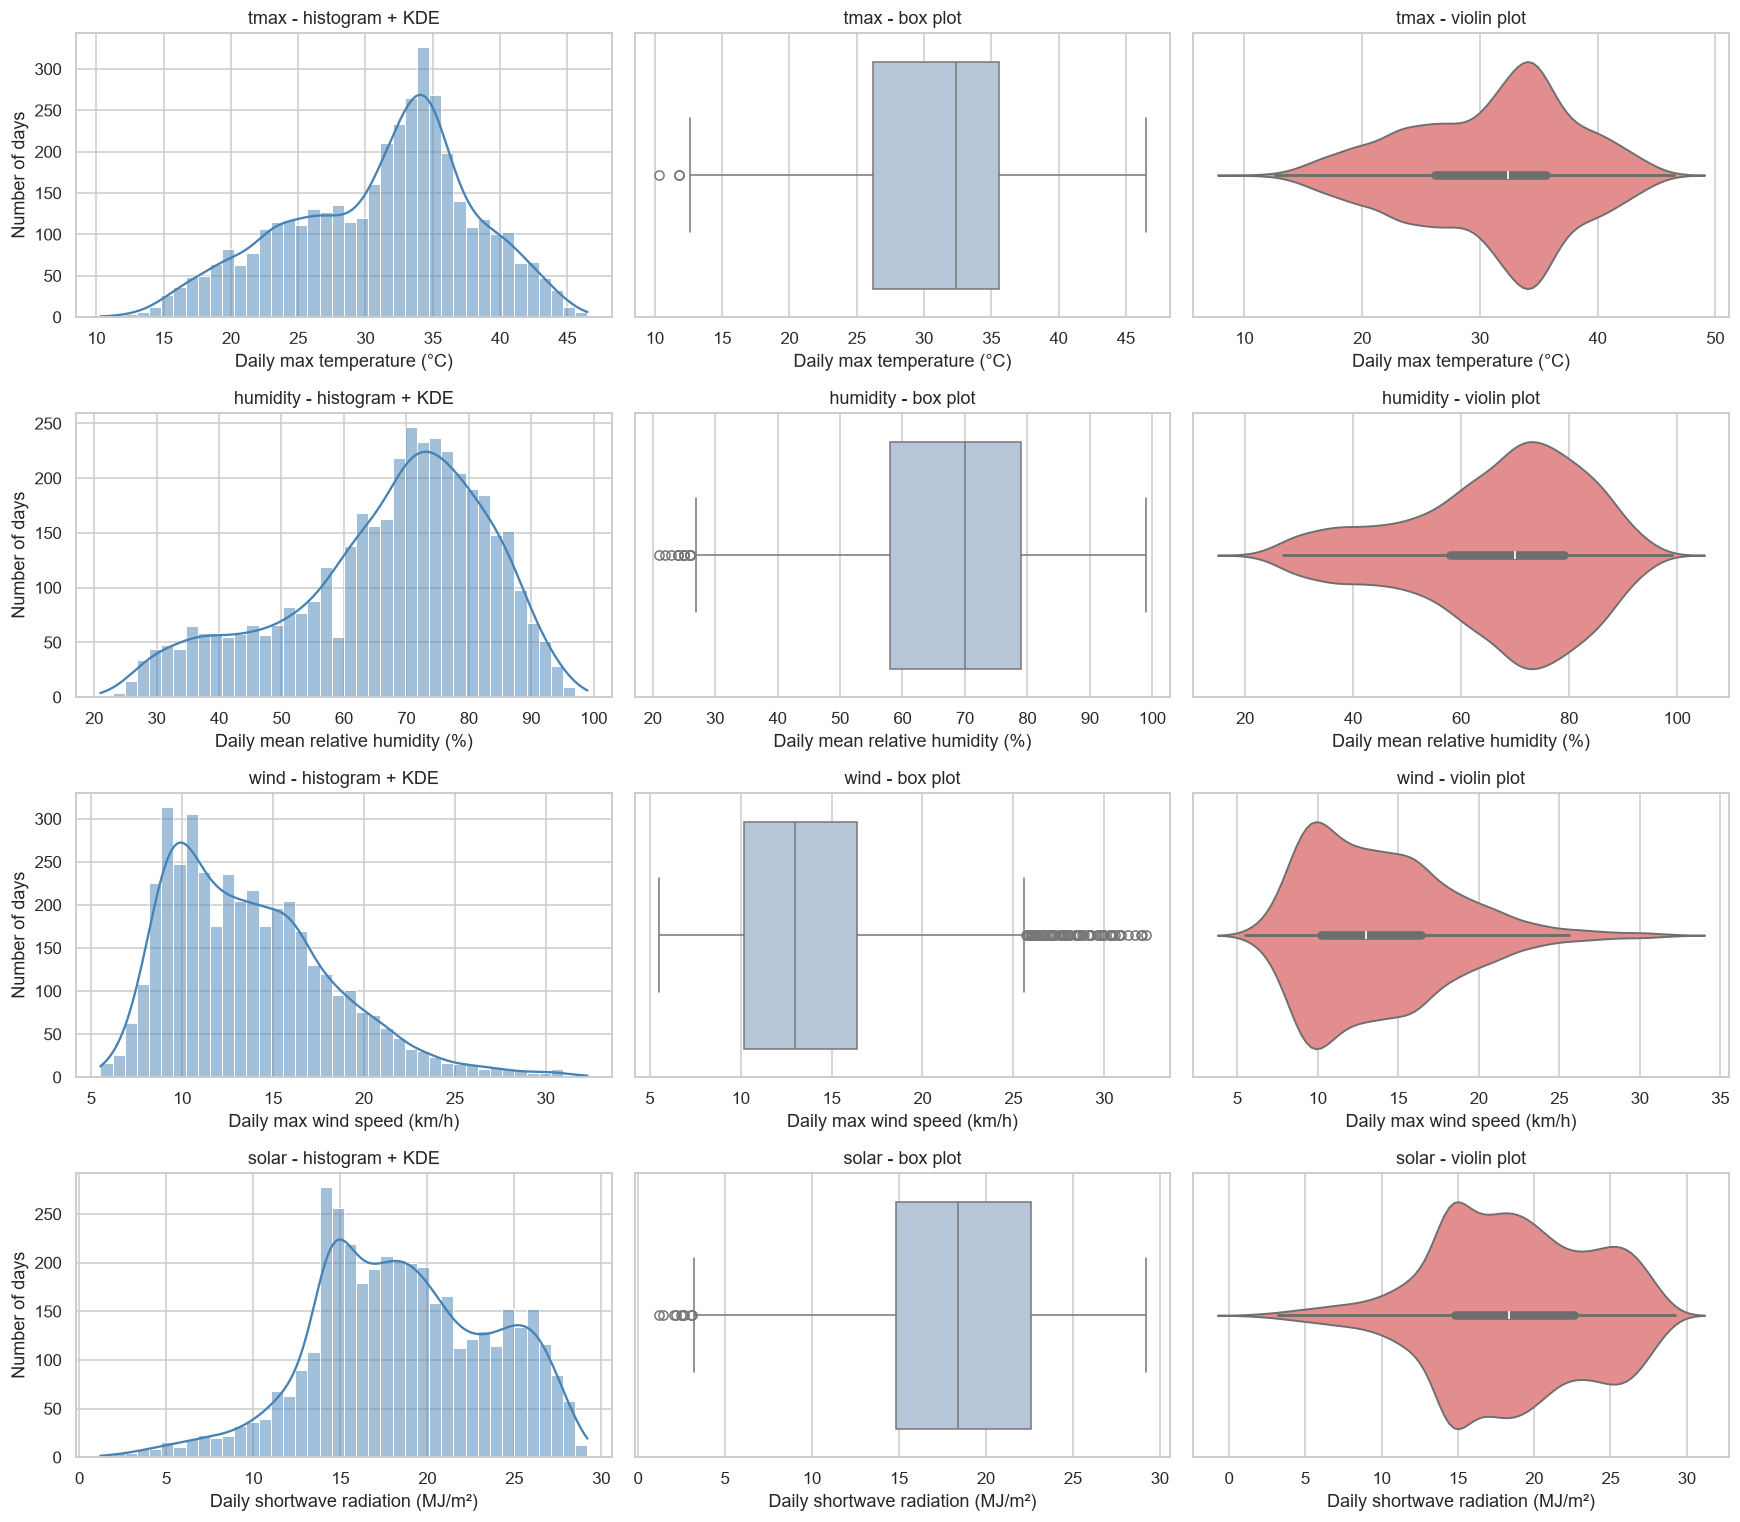

,count,mean,median,mode (0.1 rounded),min,max,range,variance,std,25%,50%,75%,IQR,skewness,kurtosis (excess)
tmax,4018.0,31.100,32.40,34.3,10.3,46.50,36.20,46.360,6.809,26.20,32.40,35.600,9.400,-0.381,-0.459
humidity,4018.0,66.961,70.00,74.0,21.0,99.00,78.00,256.879,16.027,58.00,70.00,79.000,21.000,-0.674,-0.217
wind,4018.0,13.767,13.00,9.4,5.5,32.30,26.80,20.686,4.548,10.20,13.00,16.400,6.200,0.899,0.753
solar,4018.0,18.599,18.37,14.5,1.2,29.21,28.01,26.474,5.145,14.84,18.37,22.625,7.785,-0.171,-0.279


In [18]:
fig, ax = plt.subplots(4, 3, figsize=(16, 14))
for i, v in enumerate(VARS):
    s = eda[v].dropna()
    sns.histplot(s, kde=True, bins=40, ax=ax[i, 0], color="steelblue")
    ax[i, 0].set_title(f"{v} - histogram + KDE"); ax[i, 0].set_xlabel(LABELS[v]); ax[i, 0].set_ylabel("Number of days")
    sns.boxplot(x=s, ax=ax[i, 1], color="lightsteelblue")
    ax[i, 1].set_title(f"{v} - box plot"); ax[i, 1].set_xlabel(LABELS[v])
    sns.violinplot(x=s, ax=ax[i, 2], color="lightcoral")
    ax[i, 2].set_title(f"{v} - violin plot"); ax[i, 2].set_xlabel(LABELS[v])
plt.tight_layout(); save_fig("e1_univariate"); plt.show()
display(full_describe(eda, VARS))

HISTORICAL TIME ANALYSIS

saved -> reports\eda\e2_timeseries.png


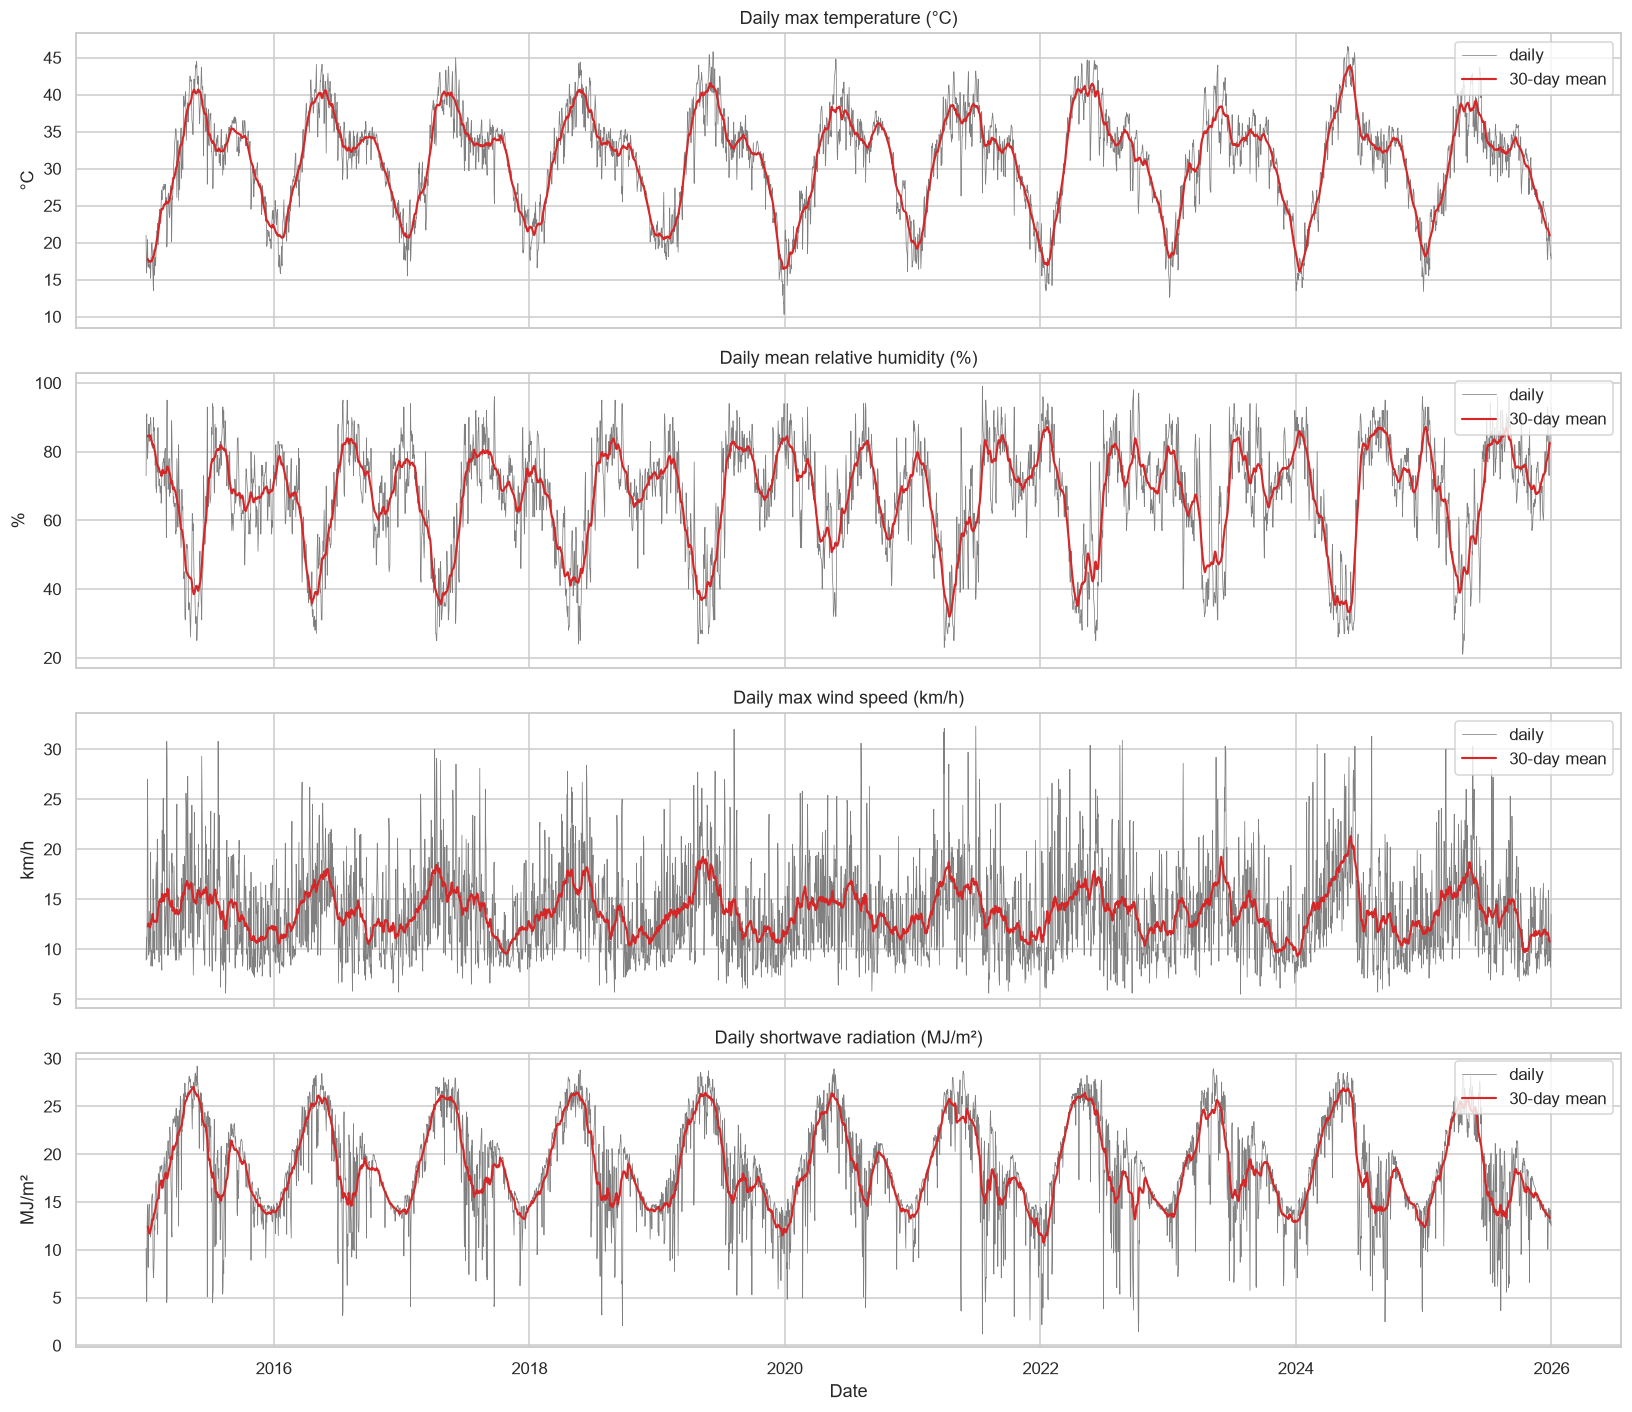

In [19]:
fig, ax = plt.subplots(4, 1, figsize=(15, 13), sharex=True)
for a, v in zip(ax, VARS):
    a.plot(eda.index, eda[v], lw=.5, color="gray", label="daily")
    a.plot(eda.index, eda[v].rolling(30, center=True, min_periods=20).mean(), lw=1.4, color="tab:red", label="30-day mean")
    a.set_ylabel(UNITS[v]); a.set_title(LABELS[v]); a.legend(loc="upper right")
ax[-1].set_xlabel("Date")
plt.tight_layout(); save_fig("e2_timeseries"); plt.show()

MONTHLY ANALYSIS

,tmax_mean,tmax_median,tmax_max,tmax_min,tmax_std,humidity_mean,wind_mean,solar_mean
Jan,19.30,19.1,26.8,12.6,2.91,80.16,12.21,13.80
Feb,24.72,24.8,33.4,14.2,3.13,70.35,13.85,17.59
Mar,30.14,30.3,39.9,18.5,4.17,61.55,14.75,21.40
Apr,37.15,37.7,44.2,25.7,3.42,42.20,16.13,24.93
May,39.19,39.6,46.5,26.3,3.55,45.90,16.65,25.68
Jun,38.39,38.5,45.8,27.9,3.59,56.54,16.39,22.75
Jul,34.08,34.2,42.4,26.7,2.67,78.45,13.92,16.89
Aug,33.35,33.4,37.5,28.1,1.80,80.44,13.81,16.17
Sep,33.60,34.0,38.0,25.3,2.41,77.48,13.18,17.25
Oct,32.84,33.4,37.0,23.7,2.31,68.21,11.36,17.95


saved -> reports\eda\e3_monthly.png


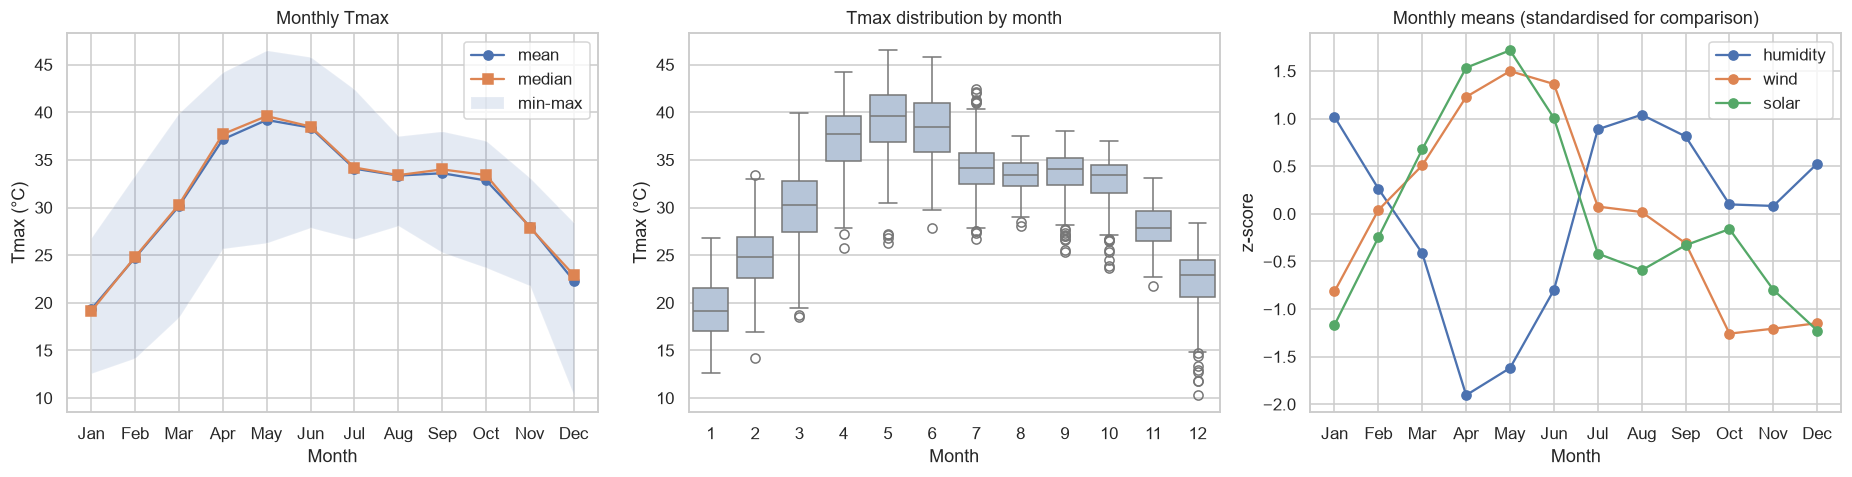

In [20]:
monthly = eda.groupby("month").agg(
    tmax_mean=("tmax", "mean"), tmax_median=("tmax", "median"), tmax_max=("tmax", "max"),
    tmax_min=("tmax", "min"), tmax_std=("tmax", "std"),
    humidity_mean=("humidity", "mean"), wind_mean=("wind", "mean"), solar_mean=("solar", "mean")).round(2)
monthly.index = MONTH_NAMES
display(monthly)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(MONTH_NAMES, monthly["tmax_mean"], marker="o", label="mean")
ax[0].plot(MONTH_NAMES, monthly["tmax_median"], marker="s", label="median")
ax[0].fill_between(MONTH_NAMES, monthly["tmax_min"], monthly["tmax_max"], alpha=.15, label="min-max")
ax[0].set_title("Monthly Tmax"); ax[0].set_xlabel("Month"); ax[0].set_ylabel("Tmax (°C)"); ax[0].legend()
sns.boxplot(data=eda, x="month", y="tmax", ax=ax[1], color="lightsteelblue")
ax[1].set_title("Tmax distribution by month"); ax[1].set_xlabel("Month"); ax[1].set_ylabel("Tmax (°C)")
for v in ["humidity", "wind", "solar"]:
    z = (monthly[f"{v}_mean"] - monthly[f"{v}_mean"].mean()) / monthly[f"{v}_mean"].std()
    ax[2].plot(MONTH_NAMES, z, marker="o", label=v)
ax[2].set_title("Monthly means (standardised for comparison)"); ax[2].set_xlabel("Month"); ax[2].set_ylabel("z-score"); ax[2].legend()
plt.tight_layout(); save_fig("e3_monthly"); plt.show()
monthly.to_csv(DIRS["eda"] / "monthly_stats.csv")

ANNUAL ANALYSIS

,tmax_mean,tmax_max,tmax_min,tmax_std,humidity_mean,wind_mean,solar_mean
year,,,,,,,
2015,30.64,44.5,13.5,6.91,66.83,13.79,18.68
2016,31.75,44.1,15.8,6.12,65.94,13.51,18.80
2017,31.47,45.0,15.5,6.46,65.23,13.71,18.94
2018,31.52,44.4,16.6,6.21,65.21,13.70,18.85
2019,30.74,45.8,10.3,7.73,66.90,13.78,18.42
2020,30.59,44.8,14.2,6.72,67.72,13.84,18.82
2021,31.28,43.2,16.4,6.47,66.43,13.89,18.64
2022,31.51,44.7,13.5,7.68,67.29,14.09,18.60
2023,30.87,44.0,12.6,6.24,68.07,13.37,18.38


saved -> reports\eda\e4_annual.png


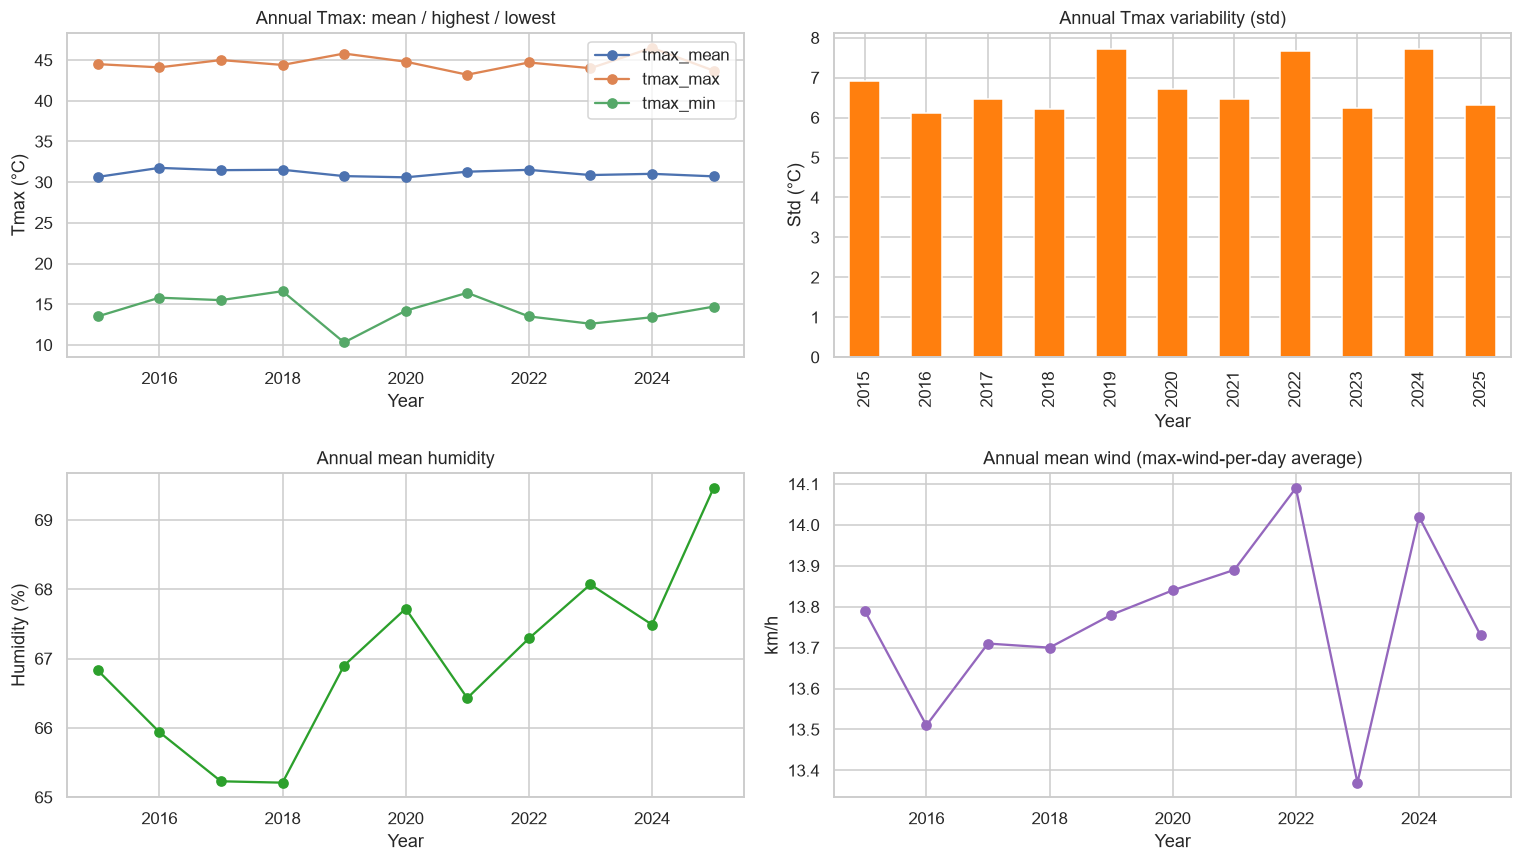

In [21]:
annual = eda.groupby("year").agg(
    tmax_mean=("tmax", "mean"), tmax_max=("tmax", "max"), tmax_min=("tmax", "min"), tmax_std=("tmax", "std"),
    humidity_mean=("humidity", "mean"), wind_mean=("wind", "mean"), solar_mean=("solar", "mean")).round(2)
display(annual)

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
annual[["tmax_mean", "tmax_max", "tmax_min"]].plot(marker="o", ax=ax[0, 0])
ax[0, 0].set_title("Annual Tmax: mean / highest / lowest"); ax[0, 0].set_xlabel("Year"); ax[0, 0].set_ylabel("Tmax (°C)")
annual["tmax_std"].plot.bar(ax=ax[0, 1], color="tab:orange")
ax[0, 1].set_title("Annual Tmax variability (std)"); ax[0, 1].set_xlabel("Year"); ax[0, 1].set_ylabel("Std (°C)")
annual["humidity_mean"].plot(marker="o", ax=ax[1, 0], color="tab:green")
ax[1, 0].set_title("Annual mean humidity"); ax[1, 0].set_xlabel("Year"); ax[1, 0].set_ylabel("Humidity (%)")
annual[["wind_mean"]].plot(marker="o", ax=ax[1, 1], color="tab:purple", legend=False)
ax[1, 1].set_title("Annual mean wind (max-wind-per-day average)"); ax[1, 1].set_xlabel("Year"); ax[1, 1].set_ylabel("km/h")
plt.tight_layout(); save_fig("e4_annual"); plt.show()
annual.to_csv(DIRS["eda"] / "annual_stats.csv")

SEASONAL ANALYSIS

tmax       humidity          wind        solar      
               mean   std     mean    std   mean   std   mean   std
season                                                             
Winter        22.03  3.78    74.90   9.34  12.50  3.92  14.90  3.01
Pre-monsoon   35.48  5.39    49.97  14.47  15.84  4.49  23.99  3.31
Monsoon       34.84  3.38    73.33  14.38  14.32  4.81  18.24  5.20
Post-monsoon  30.45  3.29    68.11   8.33  11.41  3.07  16.66  2.55

saved -> reports\eda\e5_seasonal.png


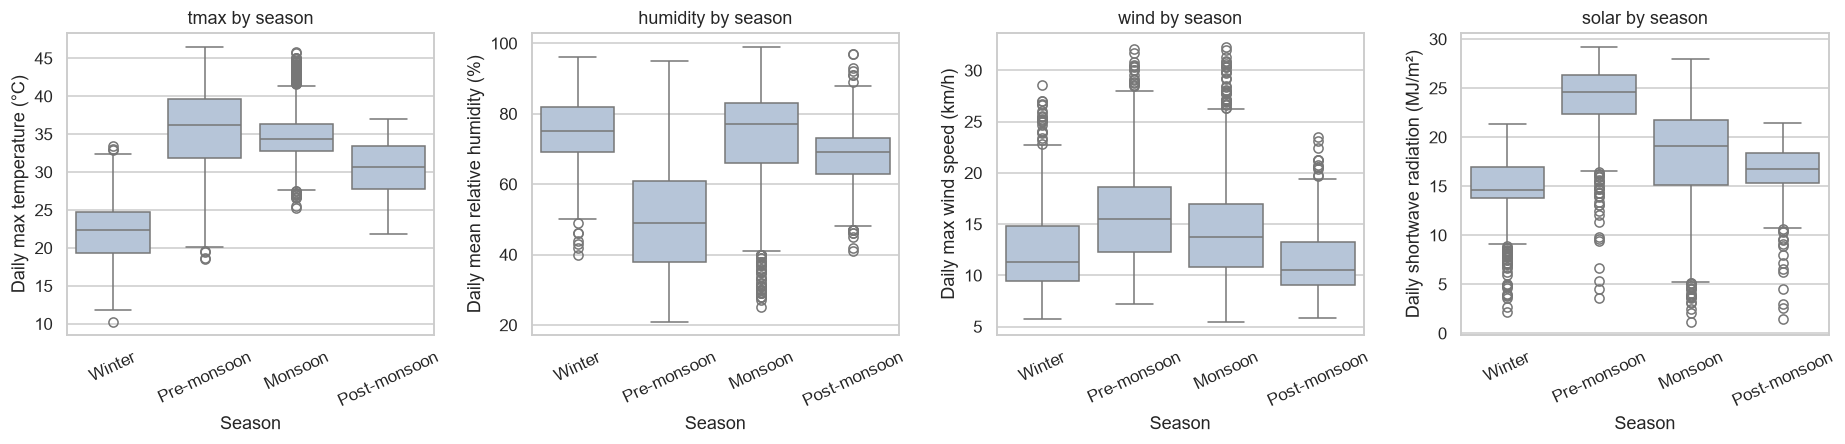

March-June focus:


tmax       humidity         wind        solar       
      mean   max     mean   max   mean   max   mean    max
Mar  30.14  39.9    61.55  95.0  14.75  31.7  21.40  26.08
Apr  37.15  44.2    42.20  82.0  16.13  32.1  24.93  28.43
May  39.19  46.5    45.90  88.0  16.65  30.4  25.68  29.21
Jun  38.39  45.8    56.54  93.0  16.39  32.3  22.75  27.98

In [22]:
season_stats = eda.groupby("season")[VARS].agg(["mean", "std"]).reindex(SEASON_ORDER).round(2)
display(season_stats)

fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
for a, v in zip(ax, VARS):
    sns.boxplot(data=eda, x="season", y=v, order=SEASON_ORDER, ax=a, color="lightsteelblue")
    a.set_title(f"{v} by season"); a.set_xlabel("Season"); a.set_ylabel(LABELS[v]); a.tick_params(axis="x", rotation=25)
plt.tight_layout(); save_fig("e5_seasonal"); plt.show()

print("March-June focus:")
display(summer.groupby("month")[VARS].agg(["mean", "max"]).round(2).set_axis(MONTH_NAMES[2:6], axis=0))

EXTREME TEMP ANALYSIS

,days,% of all days
>= 35 °C,1200.0,29.87
>= 40 °C,363.0,9.03
>= 42 °C,165.0,4.11
>= 45 °C,13.0,0.32
>= 47 °C,0.0,0.00


saved -> reports\eda\e6_extreme_frequency.png


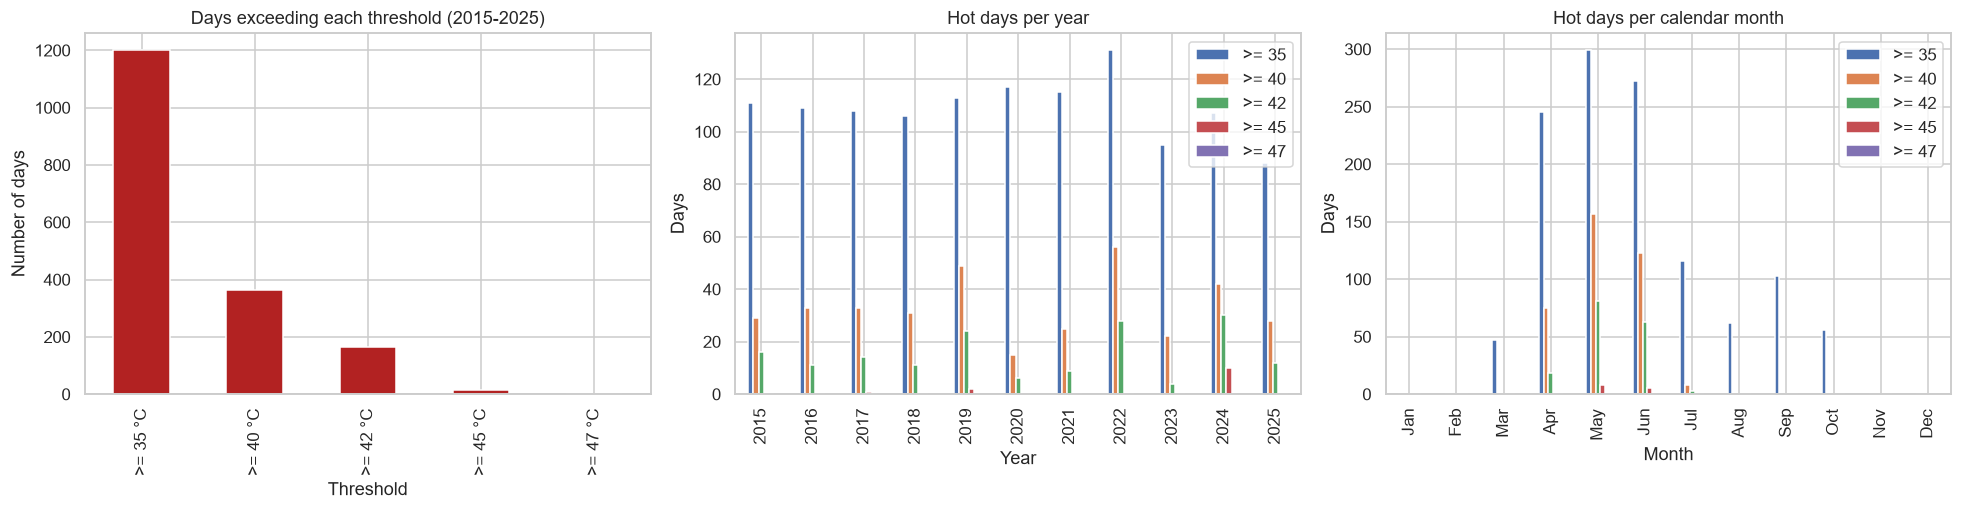

,>= 35,>= 40,>= 42,>= 45,>= 47
year,,,,,
2015,111,29,16,0,0
2016,109,33,11,0,0
2017,108,33,14,1,0
2018,106,31,11,0,0
2019,113,49,24,2,0
2020,117,15,6,0,0
2021,115,25,9,0,0
2022,131,56,28,0,0
2023,95,22,4,0,0



Longest runs with Tmax >= 40 °C:


,start,end,length
64,2024-05-14,2024-06-19,37
34,2019-05-26,2019-06-15,21
55,2022-05-28,2022-06-15,19
2,2015-05-18,2015-05-31,14
7,2016-05-12,2016-05-23,12
24,2018-05-19,2018-05-29,11
54,2022-05-11,2022-05-21,11
30,2019-04-23,2019-05-02,10



Longest runs with Tmax >= 42 °C:


,start,end,length
36,2022-06-01,2022-06-13,13
41,2024-05-25,2024-06-05,12
43,2024-06-09,2024-06-19,11
17,2018-05-21,2018-05-29,9
3,2015-05-21,2015-05-28,8
21,2019-05-27,2019-06-02,7
26,2020-05-22,2020-05-27,6
8,2016-05-15,2016-05-19,5



Longest runs with Tmax >= 45 °C:


,start,end,length
4,2024-05-26,2024-05-31,6
6,2024-06-16,2024-06-17,2
0,2017-06-04,2017-06-04,1
2,2019-06-10,2019-06-10,1
1,2019-05-30,2019-05-30,1
3,2024-05-19,2024-05-19,1
5,2024-06-12,2024-06-12,1


Hottest 15 days:


,tmax (°C)
date,
2024-05-28,46.5
2024-05-29,46.4
2024-05-31,46.4
2024-05-30,46.0
2019-06-10,45.8
2024-06-17,45.7
2024-05-27,45.5
2019-05-30,45.4
2024-05-26,45.4


Days with Tmax >= 45 °C: 13


,tmax,humidity,wind,solar
date,,,,
2017-06-04,45.0,30.0,20.8,27.52
2019-05-30,45.4,29.0,17.9,27.90
2019-06-10,45.8,35.0,14.1,26.93
2024-05-19,45.0,27.0,27.5,26.74
2024-05-26,45.4,31.0,18.0,28.14
2024-05-27,45.5,32.0,16.3,28.16
2024-05-28,46.5,29.0,17.7,28.57
2024-05-29,46.4,28.0,14.3,27.03
2024-05-30,46.0,29.0,19.2,27.08


In [23]:
exceed = pd.DataFrame({
    f">= {t} °C": [int((eda["tmax"] >= t).sum()), round((eda["tmax"] >= t).mean() * 100, 2)] for t in HOT_THRESHOLDS
}, index=["days", "% of all days"]).T
display(exceed)

yearly_counts = pd.DataFrame({f">= {t}": eda.groupby("year")["tmax"].apply(lambda s, t=t: int((s >= t).sum()))
                              for t in HOT_THRESHOLDS})
monthly_counts = pd.DataFrame({f">= {t}": eda.groupby("month")["tmax"].apply(lambda s, t=t: int((s >= t).sum()))
                               for t in HOT_THRESHOLDS})
monthly_counts.index = MONTH_NAMES

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
exceed["days"].plot.bar(ax=ax[0], color="firebrick")
ax[0].set_title("Days exceeding each threshold (2015-2025)"); ax[0].set_xlabel("Threshold"); ax[0].set_ylabel("Number of days")
yearly_counts.plot.bar(ax=ax[1]); ax[1].set_title("Hot days per year"); ax[1].set_xlabel("Year"); ax[1].set_ylabel("Days")
monthly_counts.plot.bar(ax=ax[2]); ax[2].set_title("Hot days per calendar month"); ax[2].set_xlabel("Month"); ax[2].set_ylabel("Days")
plt.tight_layout(); save_fig("e6_extreme_frequency"); plt.show()
display(yearly_counts)

# Consecutive hot-day runs
for t in (40, 42, 45):
    runs = run_lengths(eda["tmax"] >= t).sort_values("length", ascending=False)
    print(f"\nLongest runs with Tmax >= {t} °C:")
    display(runs.head(8) if len(runs) else "no such days")

print("Hottest 15 days:")
display(eda["tmax"].nlargest(15).to_frame("tmax (°C)"))
hot45 = eda.loc[eda["tmax"] >= 45, ["tmax", "humidity", "wind", "solar"]]
print(f"Days with Tmax >= 45 °C: {len(hot45)}")
display(hot45)
hot45.to_csv(DIRS["eda"] / "extreme_days_ge45.csv")

CORRELATION ANALYSIS

saved -> reports\eda\e7_correlation.png


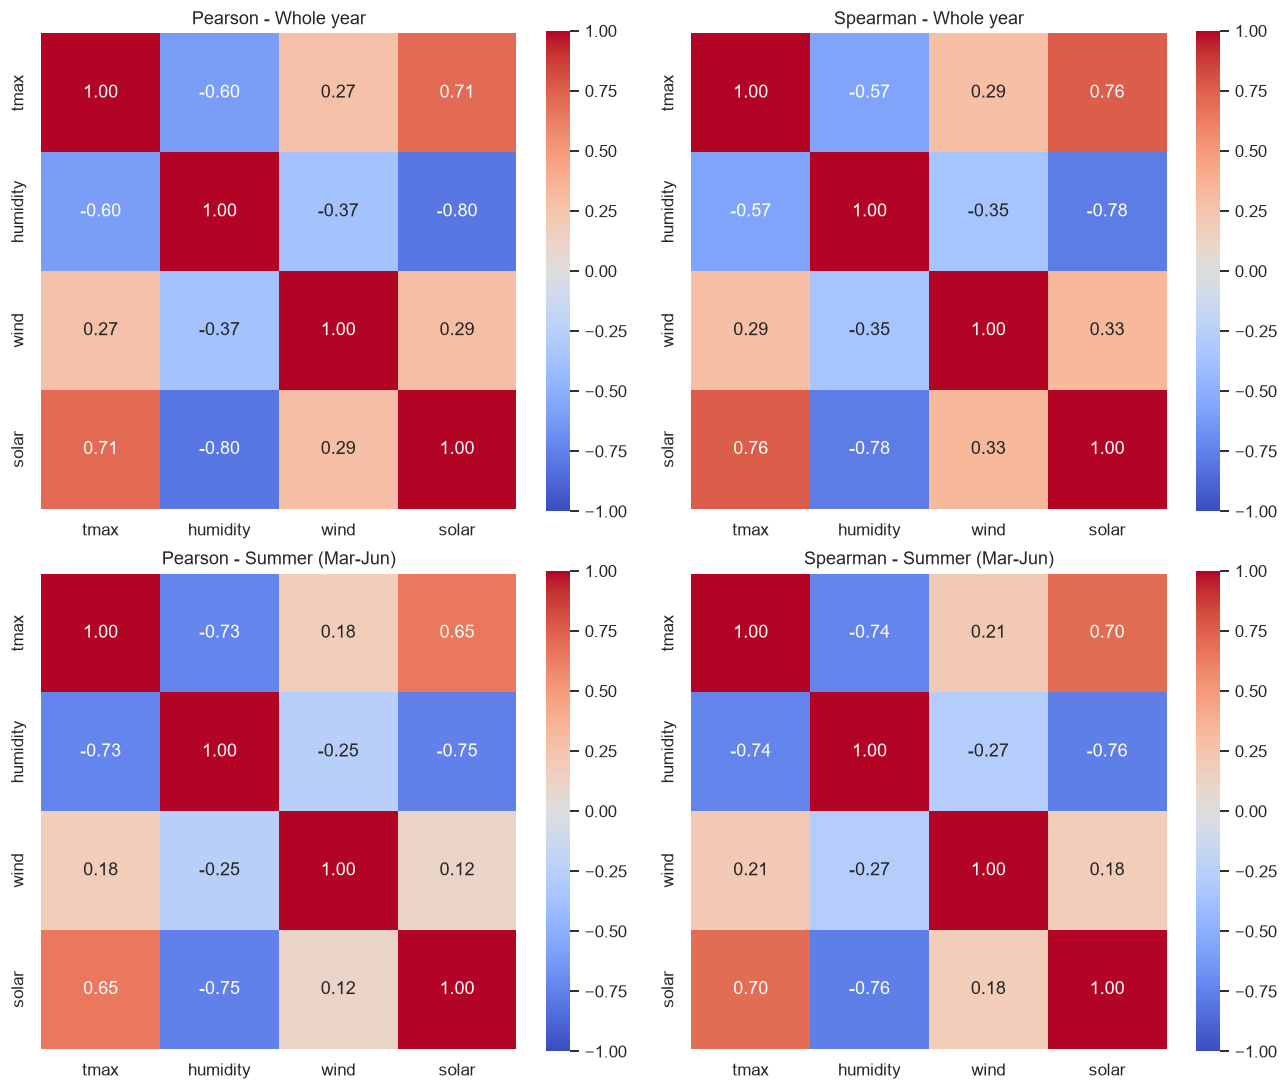

In [24]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
for r, (name, data) in enumerate([("Whole year", eda), ("Summer (Mar-Jun)", summer)]):
    for c, method in enumerate(["pearson", "spearman"]):
        corr = data[VARS].corr(method=method)
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[r, c], square=True)
        ax[r, c].set_title(f"{method.title()} - {name}")
plt.tight_layout(); save_fig("e7_correlation"); plt.show()

saved -> reports\eda\e8_bivariate.png


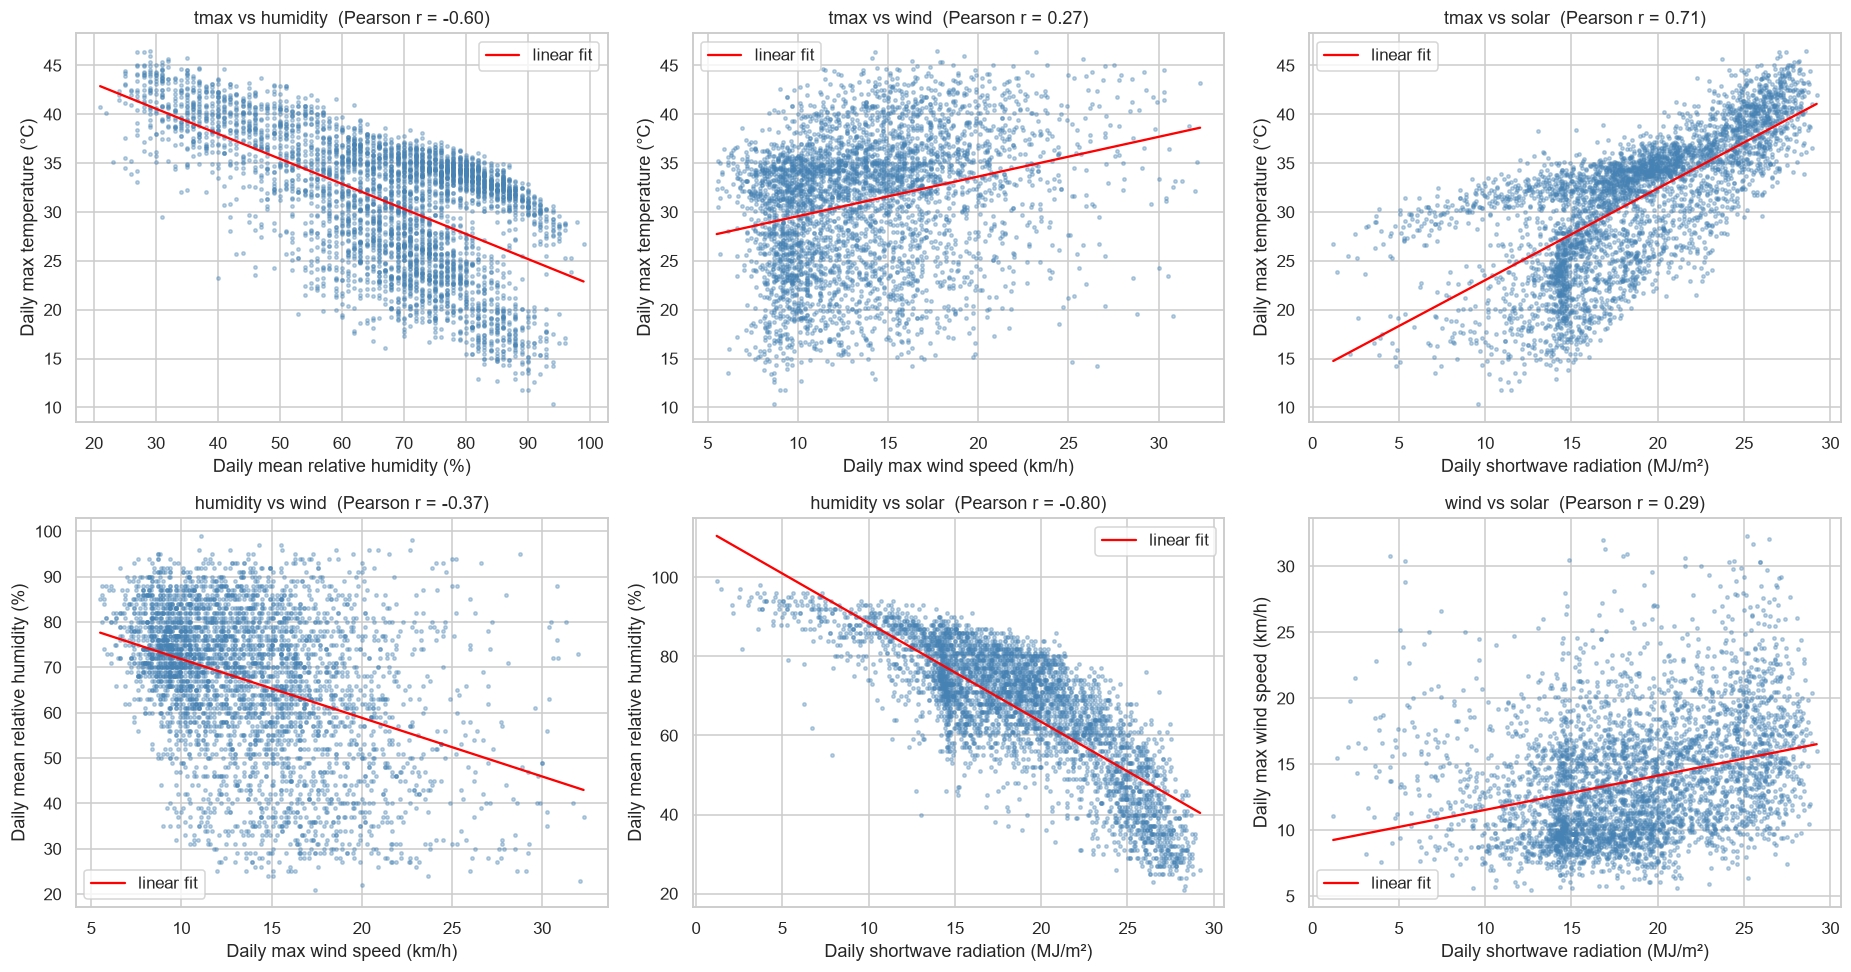

In [25]:
pairs = [("humidity", "tmax"), ("wind", "tmax"), ("solar", "tmax"),
         ("wind", "humidity"), ("solar", "humidity"), ("solar", "wind")]
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for a, (x, y) in zip(ax.ravel(), pairs):
    d = eda[[x, y]].dropna()
    a.scatter(d[x], d[y], s=5, alpha=.35, color="steelblue")
    slope, intercept = np.polyfit(d[x], d[y], 1)
    xs = np.linspace(d[x].min(), d[x].max(), 50)
    a.plot(xs, slope * xs + intercept, color="red", lw=1.5, label="linear fit")
    r = d[x].corr(d[y])
    a.set_title(f"{y} vs {x}  (Pearson r = {r:.2f})")
    a.set_xlabel(LABELS[x]); a.set_ylabel(LABELS[y]); a.legend()
plt.tight_layout(); save_fig("e8_bivariate"); plt.show()

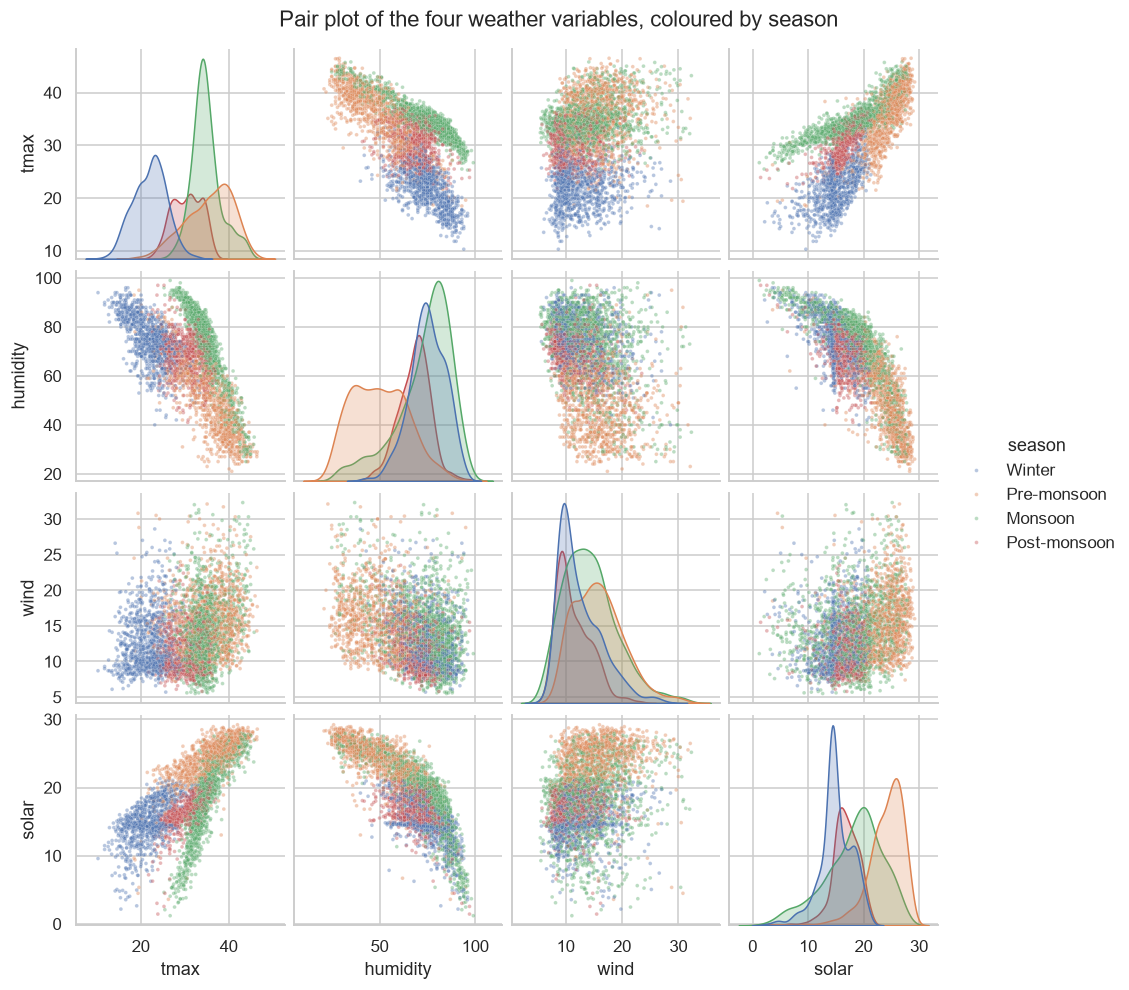

In [26]:
pp = sns.pairplot(eda[VARS + ["season"]].dropna(), hue="season", hue_order=SEASON_ORDER,
                  plot_kws={"s": 6, "alpha": .4}, diag_kind="kde", height=2.2)
pp.fig.suptitle("Pair plot of the four weather variables, coloured by season", y=1.02)
pp.savefig(DIRS["eda"] / "e9_pairplot.png", dpi=130); plt.show()

saved -> reports\eda\e10_rolling.png


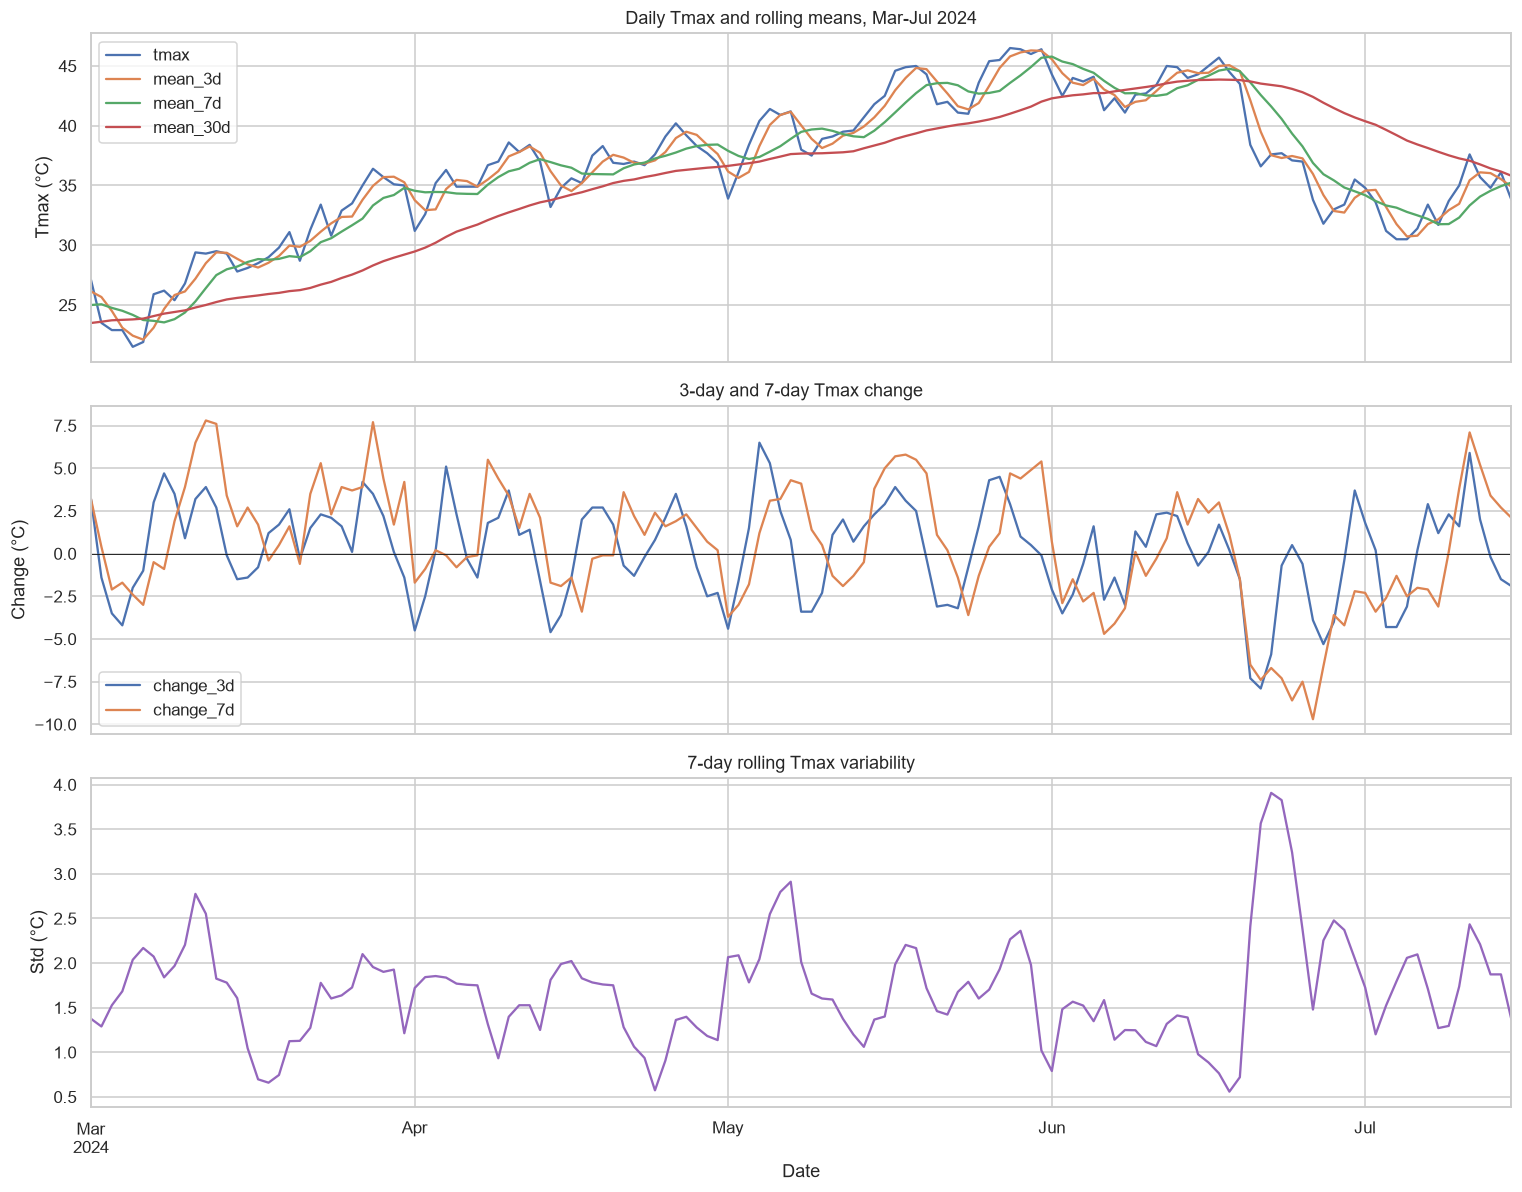

In [27]:
EXAMPLE_YEAR = 2024
t = eda["tmax"]
roll = pd.DataFrame({
    "tmax": t,
    "mean_3d": t.rolling(3).mean(), "mean_7d": t.rolling(7).mean(), "mean_30d": t.rolling(30).mean(),
    "change_3d": t - t.shift(3), "change_7d": t - t.shift(7),
    "std_7d": t.rolling(7).std(),
})                                                           # all backward-looking
ex = roll.loc[f"{EXAMPLE_YEAR}-03-01":f"{EXAMPLE_YEAR}-07-15"]
fig, ax = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
ex[["tmax", "mean_3d", "mean_7d", "mean_30d"]].plot(ax=ax[0]); ax[0].set_ylabel("Tmax (°C)")
ax[0].set_title(f"Daily Tmax and rolling means, Mar-Jul {EXAMPLE_YEAR}")
ex[["change_3d", "change_7d"]].plot(ax=ax[1]); ax[1].axhline(0, color="k", lw=.6); ax[1].set_ylabel("Change (°C)")
ax[1].set_title("3-day and 7-day Tmax change")
ex["std_7d"].plot(ax=ax[2], color="tab:purple"); ax[2].set_ylabel("Std (°C)"); ax[2].set_xlabel("Date")
ax[2].set_title("7-day rolling Tmax variability")
plt.tight_layout(); save_fig("e10_rolling"); plt.show()

lag_days,lag1,lag2,lag3
Pearson (all months),,,
humidity,-0.589,-0.563,-0.544
solar,0.705,0.684,0.667
tmax,0.964,0.932,0.908
wind,0.236,0.252,0.260


lag_days,lag1,lag2,lag3
Pearson (Mar-Jun),,,
humidity,-0.703,-0.640,-0.593
solar,0.690,0.656,0.621
tmax,0.919,0.838,0.780
wind,0.093,0.112,0.127


saved -> reports\eda\e11_lag_scatter.png


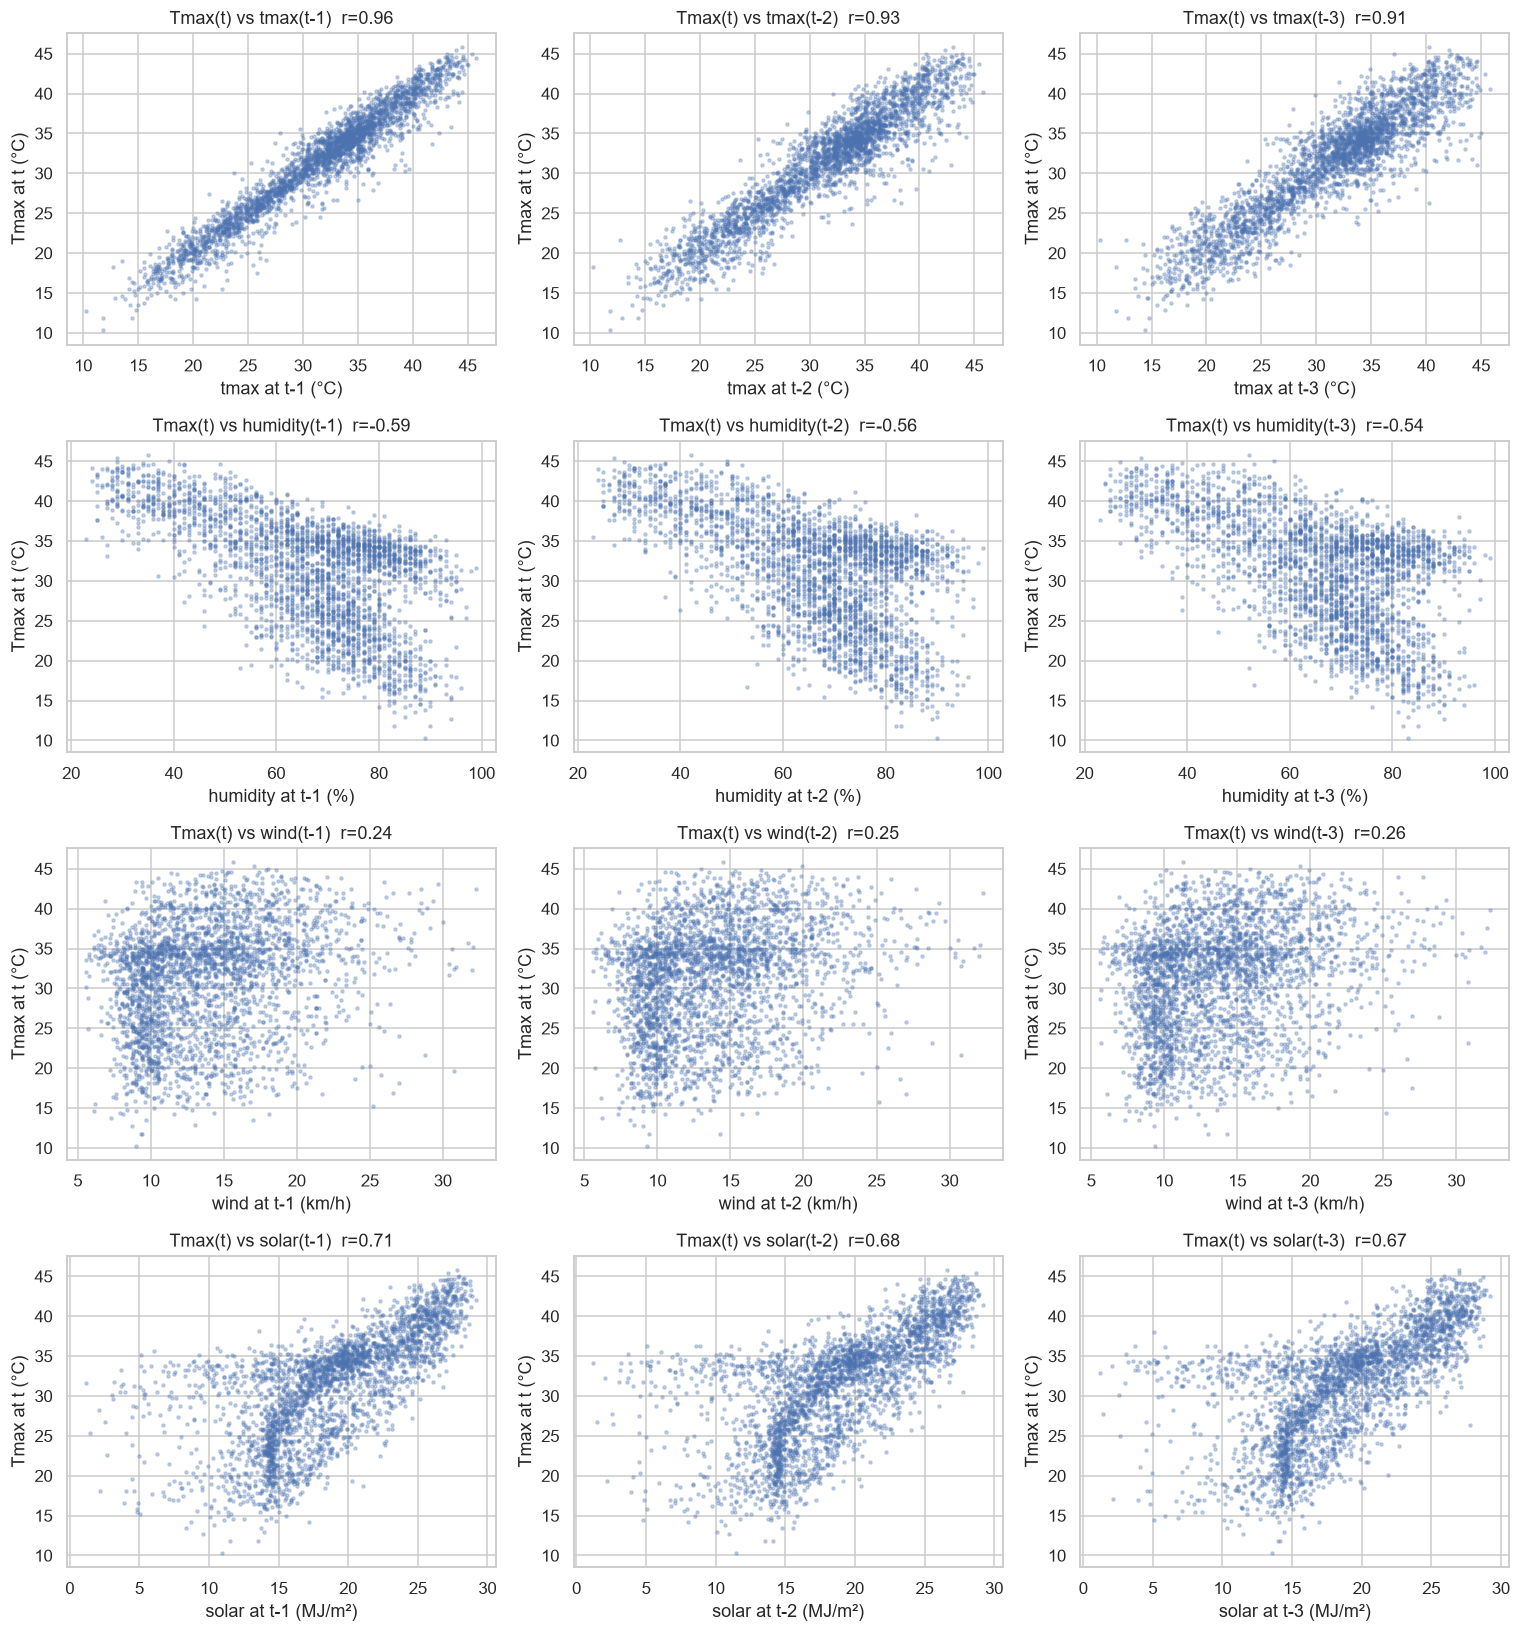

In [28]:
dev = eda.loc[:TRAIN_END, VARS]
dev_summer = dev[dev.index.month.isin(SUMMER_MONTHS)]
rows = []
for v in VARS:
    for k in (1, 2, 3):
        lagged = dev[v].shift(k)                       # date-aligned: calendar has no gaps
        both = pd.concat([dev["tmax"], lagged], axis=1).dropna()
        both_s = both[both.index.month.isin(SUMMER_MONTHS)]
        rows.append({"variable": v, "lag_days": k,
                     "pearson_all": both.iloc[:, 0].corr(both.iloc[:, 1]),
                     "spearman_all": both.iloc[:, 0].corr(both.iloc[:, 1], method="spearman"),
                     "pearson_summer": both_s.iloc[:, 0].corr(both_s.iloc[:, 1])})
lag_table = pd.DataFrame(rows).round(3)
display(lag_table.pivot(index="variable", columns="lag_days", values="pearson_all").add_prefix("lag").rename_axis("Pearson (all months)"))
display(lag_table.pivot(index="variable", columns="lag_days", values="pearson_summer").add_prefix("lag").rename_axis("Pearson (Mar-Jun)"))
lag_table.to_csv(DIRS["eda"] / "lag_correlations.csv", index=False)

fig, ax = plt.subplots(4, 3, figsize=(14, 15))
for i, v in enumerate(VARS):
    for j, k in enumerate((1, 2, 3)):
        d = pd.concat([dev["tmax"], dev[v].shift(k)], axis=1, keys=["y", "x"]).dropna()
        ax[i, j].scatter(d["x"], d["y"], s=4, alpha=.3)
        ax[i, j].set_title(f"Tmax(t) vs {v}(t-{k})  r={d['x'].corr(d['y']):.2f}")
        ax[i, j].set_xlabel(f"{v} at t-{k} ({UNITS[v]})"); ax[i, j].set_ylabel("Tmax at t (°C)")
plt.tight_layout(); save_fig("e11_lag_scatter"); plt.show()

saved -> reports\eda\e12_autocorrelation.png


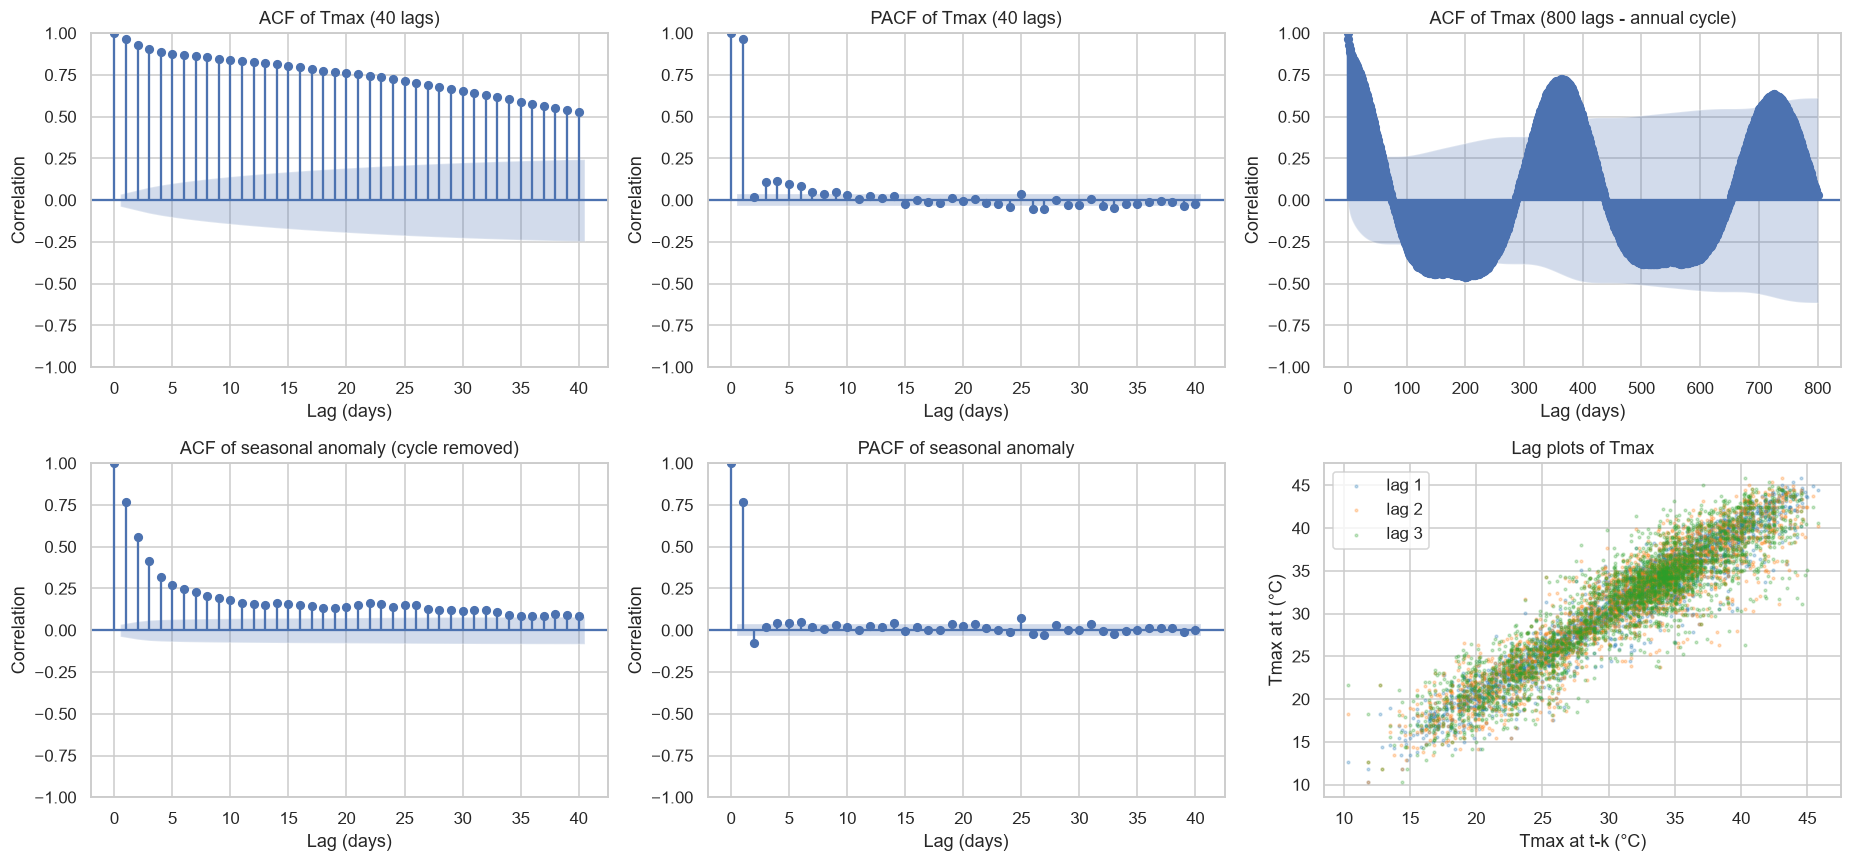

Autocorrelation of Tmax at lag 1/2/3: [0.964, 0.932, 0.908]
Autocorrelation of seasonal anomaly at lag 1/2/3: [0.77, 0.561, 0.413]


In [29]:
# statsmodels cannot handle NaN -> short gaps are interpolated for these DIAGNOSTIC plots only
tmax_dev = dev["tmax"].interpolate(limit=3).dropna()
anom_dev = seasonal_anomaly(tmax_dev).dropna()

fig, ax = plt.subplots(2, 3, figsize=(17, 8))
plot_acf(tmax_dev, lags=40, ax=ax[0, 0]);  ax[0, 0].set_title("ACF of Tmax (40 lags)")
plot_pacf(tmax_dev, lags=40, ax=ax[0, 1], method="ywm"); ax[0, 1].set_title("PACF of Tmax (40 lags)")
plot_acf(tmax_dev, lags=800, ax=ax[0, 2]); ax[0, 2].set_title("ACF of Tmax (800 lags - annual cycle)")
plot_acf(anom_dev, lags=40, ax=ax[1, 0]);  ax[1, 0].set_title("ACF of seasonal anomaly (cycle removed)")
plot_pacf(anom_dev, lags=40, ax=ax[1, 1], method="ywm"); ax[1, 1].set_title("PACF of seasonal anomaly")
for k, c in zip((1, 2, 3), ("tab:blue", "tab:orange", "tab:green")):
    ax[1, 2].scatter(tmax_dev.shift(k), tmax_dev, s=3, alpha=.25, color=c, label=f"lag {k}")
ax[1, 2].set_title("Lag plots of Tmax"); ax[1, 2].set_xlabel("Tmax at t-k (°C)"); ax[1, 2].set_ylabel("Tmax at t (°C)"); ax[1, 2].legend()
for a in ax.ravel()[:5]:
    a.set_xlabel("Lag (days)"); a.set_ylabel("Correlation")
plt.tight_layout(); save_fig("e12_autocorrelation"); plt.show()

print("Autocorrelation of Tmax at lag 1/2/3:", [round(float(tmax_dev.autocorr(k)), 3) for k in (1, 2, 3)])
print("Autocorrelation of seasonal anomaly at lag 1/2/3:", [round(float(anom_dev.autocorr(k)), 3) for k in (1, 2, 3)])

saved -> reports\eda\e13a_mean_tmax_year_month.png


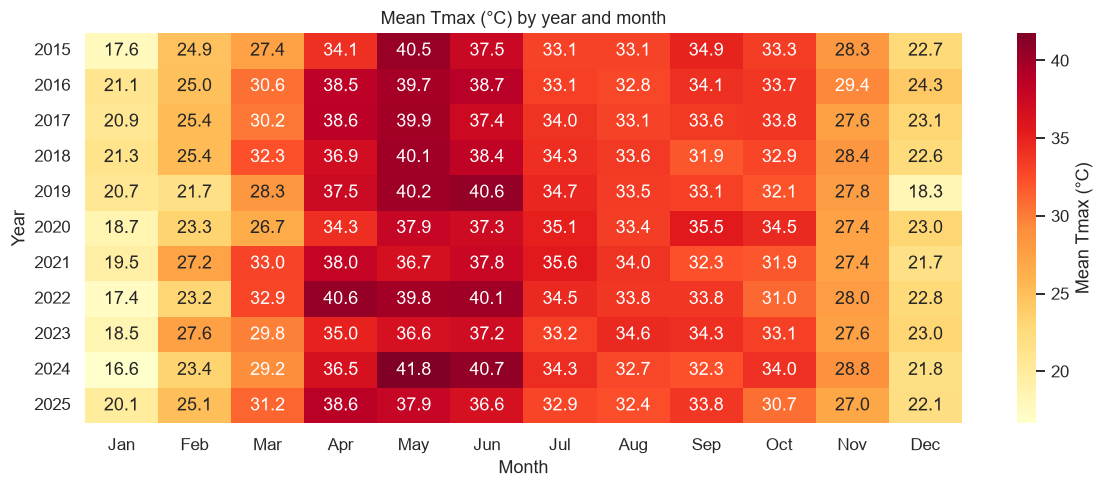

saved -> reports\eda\e13b_max_tmax_year_month.png


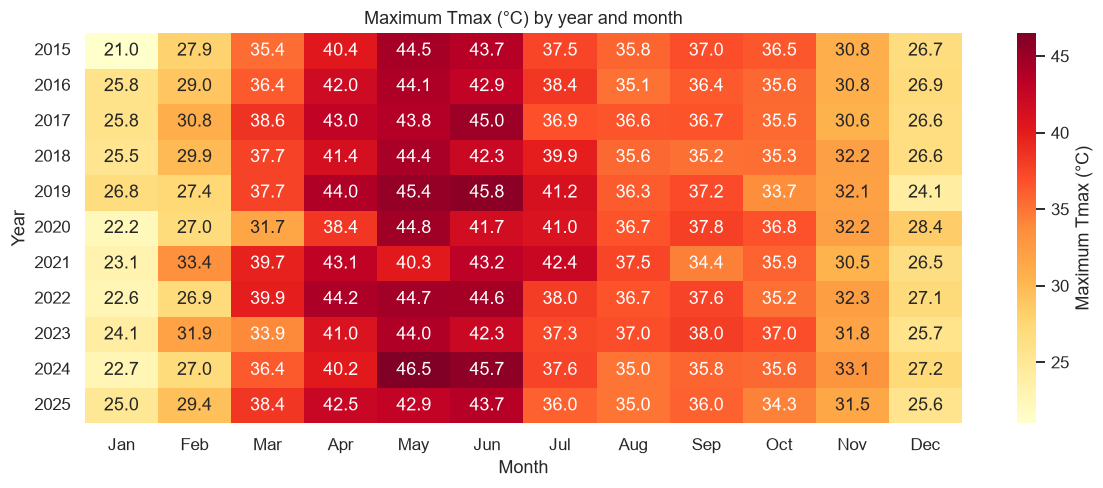

saved -> reports\eda\e13c_humidity_year_month.png


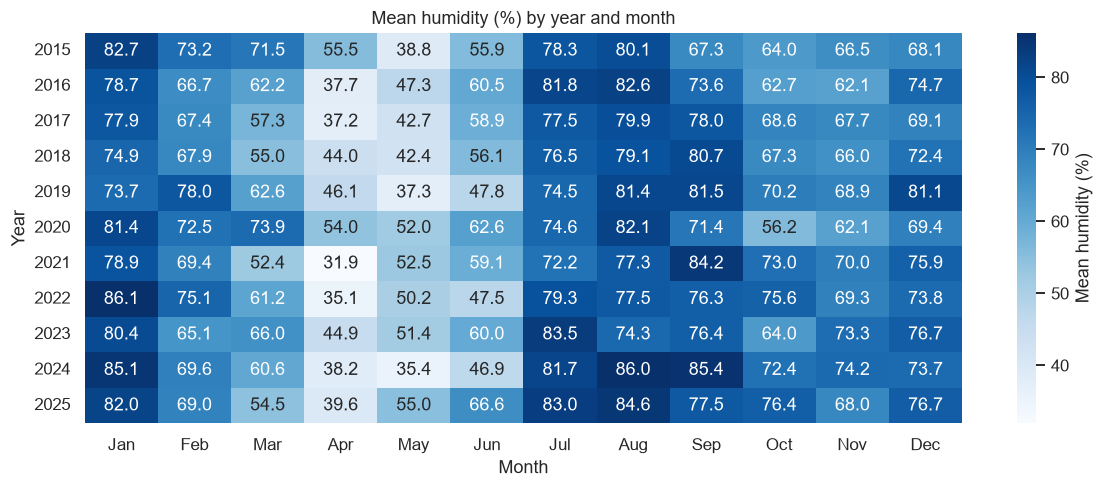

saved -> reports\eda\e13d_solar_year_month.png


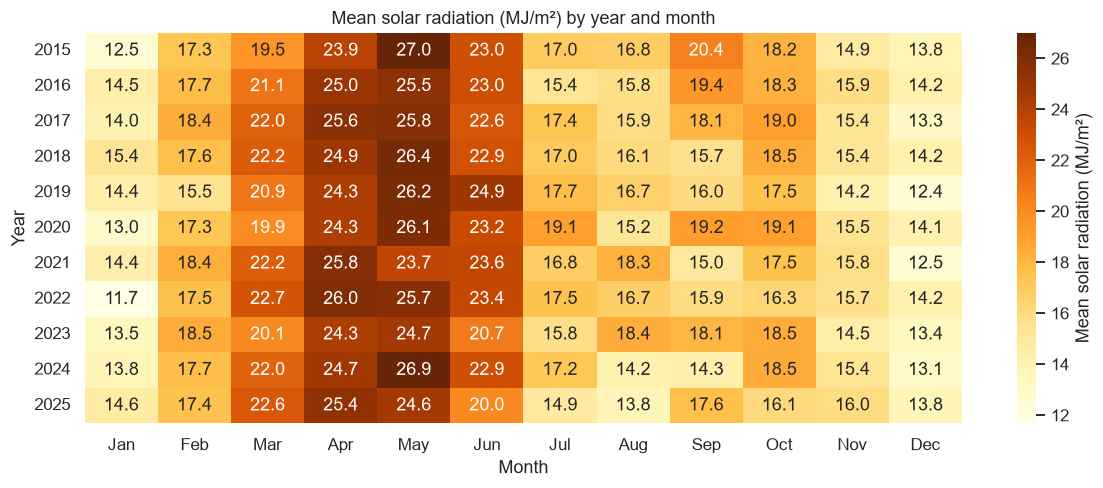

saved -> reports\eda\e13e_days_ge40_year_month.png


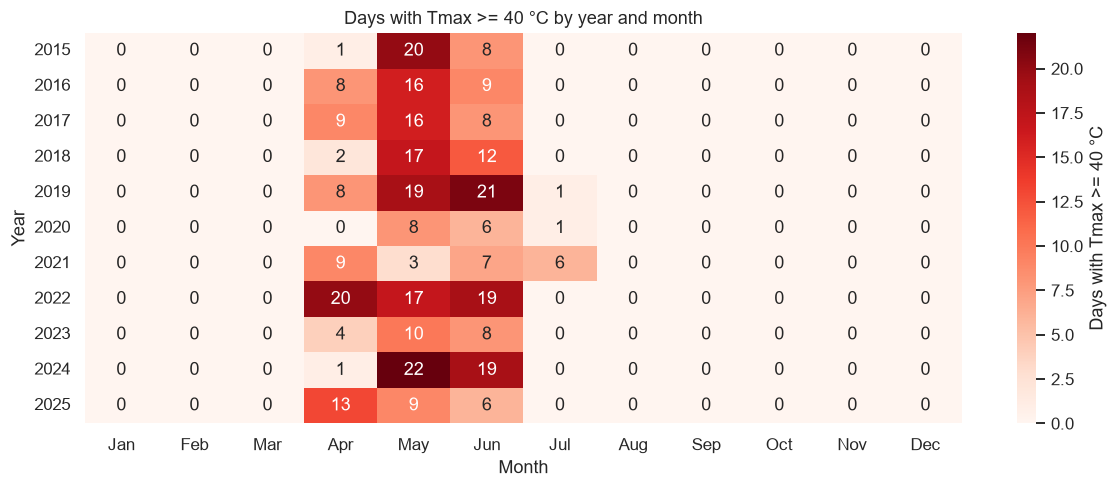

In [30]:
def ym_pivot(col, how):
    p = eda.pivot_table(index="year", columns="month", values=col, aggfunc=how)
    p.columns = [MONTH_NAMES[m - 1] for m in p.columns]
    return p

hm = [
    ("e13a_mean_tmax_year_month", "Mean Tmax (°C) by year and month", ym_pivot("tmax", "mean"), "YlOrRd"),
    ("e13b_max_tmax_year_month", "Maximum Tmax (°C) by year and month", ym_pivot("tmax", "max"), "YlOrRd"),
    ("e13c_humidity_year_month", "Mean humidity (%) by year and month", ym_pivot("humidity", "mean"), "Blues"),
    ("e13d_solar_year_month", "Mean solar radiation (MJ/m²) by year and month", ym_pivot("solar", "mean"), "YlOrBr"),
]
hot40 = eda.assign(hot=(eda["tmax"] >= 40).astype(int)).pivot_table(index="year", columns="month", values="hot", aggfunc="sum")
hot40.columns = [MONTH_NAMES[m - 1] for m in hot40.columns]
hm.append(("e13e_days_ge40_year_month", "Days with Tmax >= 40 °C by year and month", hot40, "Reds"))

for fname, title, pivot, cmap in hm:
    plt.figure(figsize=(11, 4.6))
    sns.heatmap(pivot, annot=True, fmt=".0f" if "Days" in title else ".1f", cmap=cmap, cbar_kws={"label": title.split(" by")[0]})
    plt.title(title); plt.xlabel("Month"); plt.ylabel("Year")
    plt.tight_layout(); save_fig(fname); plt.show()

humidity               wind               solar              
                 count  mean median count   mean median count   mean median
day_type                                                                   
Tmax < 40 °C       987  56.4   57.0   987  15.45   15.0   987  22.78  23.40
Tmax >= 40 °C      355  38.2   37.0   355  17.43   16.6   355  26.21  26.34

saved -> reports\eda\e14_hot_vs_cooler.png


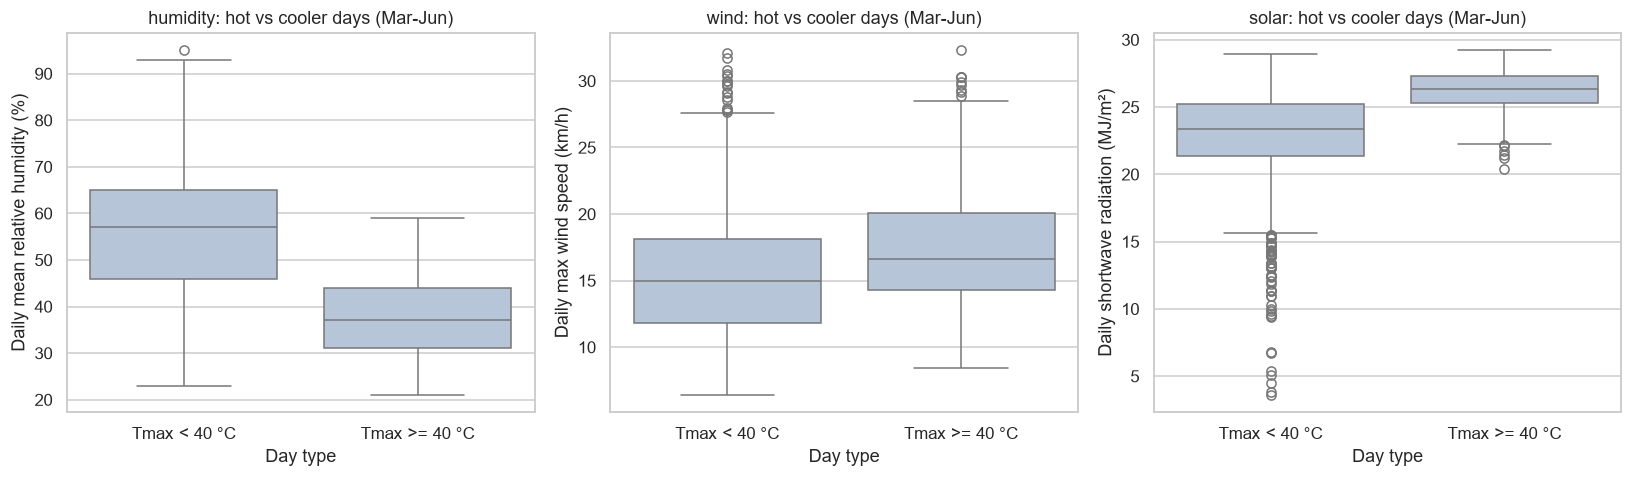

humidity: Mann-Whitney U p-value = 4.8e-92  (descriptive support only, not causation)
wind: Mann-Whitney U p-value = 5.9e-12  (descriptive support only, not causation)
solar: Mann-Whitney U p-value = 3.98e-80  (descriptive support only, not causation)


In [31]:
HOT_CUT = 40                         # exploratory cut-off within Mar-Jun
s2 = summer.copy()
s2["day_type"] = np.where(s2["tmax"] >= HOT_CUT, f"Tmax >= {HOT_CUT} °C", f"Tmax < {HOT_CUT} °C")
cmp_table = s2.groupby("day_type")[["humidity", "wind", "solar"]].agg(["count", "mean", "median"]).round(2)
display(cmp_table)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, v in zip(ax, ["humidity", "wind", "solar"]):
    sns.boxplot(data=s2, x="day_type", y=v, ax=a, color="lightsteelblue")
    a.set_title(f"{v}: hot vs cooler days (Mar-Jun)"); a.set_xlabel("Day type"); a.set_ylabel(LABELS[v])
plt.tight_layout(); save_fig("e14_hot_vs_cooler"); plt.show()

for v in ["humidity", "wind", "solar"]:
    a_ = s2.loc[s2["tmax"] >= HOT_CUT, v].dropna(); b_ = s2.loc[s2["tmax"] < HOT_CUT, v].dropna()
    if len(a_) > 5 and len(b_) > 5:
        u = stats.mannwhitneyu(a_, b_)
        print(f"{v}: Mann-Whitney U p-value = {u.pvalue:.3g}  (descriptive support only, not causation)")

In [32]:
final = pd.read_csv(CLEAN_CSV, parse_dates=["date"])
checks = {
    "clean file has exactly 5 columns (date + 4 vars)": list(final.columns) == ["date"] + VARS,
    "4,018 rows": len(final) == EXPECTED_DAYS,
    "dates unique & strictly increasing": final["date"].is_unique and final["date"].is_monotonic_increasing,
    "dates match full calendar": (final["date"].values == FULL_INDEX.values).all(),
    "no infinite values": not np.isinf(final[VARS]).any().any(),
    "humidity within [0, 100]": final["humidity"].dropna().between(0, 100).all(),
    "wind >= 0": (final["wind"].dropna() >= 0).all(),
    "solar >= 0": (final["solar"].dropna() >= 0).all(),
    "raw file unchanged": pd.read_csv(RAW_CSV, parse_dates=["date"]).equals(df_raw),
    "genuine extremes kept (max Tmax in clean == raw)": np.isclose(final["tmax"].max(), df_raw["tmax"].max()),
    "audit file exists": (DIRS["quality"] / "cleaning_audit.csv").exists(),
    "no model imported/trained": "xgboost" not in sys.modules,
}
result = pd.Series(checks, name="passed").to_frame()
display(result)
assert result["passed"].all(), "A verification check failed - review above."
print("\nAll checks passed. Next: 02_model_training.ipynb -> feature engineering, supervised rows, chronological split.")

,passed
clean file has exactly 5 columns (date + 4 vars),True
"4,018 rows",True
dates unique & strictly increasing,True
dates match full calendar,True
no infinite values,True
"humidity within [0, 100]",True
wind >= 0,True
solar >= 0,True
raw file unchanged,True
genuine extremes kept (max Tmax in clean == raw),True



All checks passed. Next: 02_model_training.ipynb -> feature engineering, supervised rows, chronological split.
